In [ ]:
# Connecting Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Changing work folder
%cd /content/drive/MyDrive/Mate_homework

/content/drive/MyDrive/Mate_homework


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Uploading dataset 1
events = pd.read_csv("events.csv")
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
# Uploading dataset 2
products = pd.read_csv("products.csv")
products.head()

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


In [ ]:
# Uploading dataset 3
countries = pd.read_csv("countries.csv")
countries.head()

,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


# 1. Data overview (огляд даних)

Набір даних містить інформацію про продажі продукції компанії, яка працює на міжнародному ринку та продає товари через звичайні магазини й інтернет-магазини.

**Основна мета проєкту** — очищення даних, проведення аналізу та виявлення цінних інсайтів щодо діяльності компанії.

Датасет складається з трьох таблиць:

* `events.csv` — дані про замовлення та продажі;
* `products.csv` — категорії товарів та їхні ідентифікатори;
* `countries.csv` — країни, регіони, підрегіони та їхні коди.

### Стовпці таблиці `events`

* `Order ID` — ідентифікатор замовлення;
* `Order Date` — дата замовлення;
* `Ship Date` — дата відправлення замовлення;
* `Order Priority` — пріоритет замовлення;
* `Country Code` — код країни;
* `Product ID` — ідентифікатор категорії товару (потребує підтвердження за даними);
* `Sales Channel` — канал продажу;
* `Units Sold` — кількість проданих одиниць товару;
* `Unit Price` — ціна продажу однієї одиниці товару;
* `Unit Cost` — собівартість однієї одиниці товару.

### Стовпці таблиці `products`

* `id` — ідентифікатор категорії товару;
* `item_type` — назва категорії товару.

### Стовпці таблиці `countries`

* `name` — назва країни;
* `alpha-2` — дволітерний код країни;
* `alpha-3` — трилітерний код країни;
* `region` — регіон;
* `sub-region` — підрегіон.

### Ключові поля, що поєднують таблиці

Для об'єднання таблиць використовуються такі пари полів:

* `events.Product ID = products.id` — за цим ідентифікатором до даних про продажі додається категорія відповідного товару;
* `events.Country Code = countries.alpha-3` — за трилітерним кодом країни до даних про продажі додаються назва країни, регіон і підрегіон.


In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


In [ ]:
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


# 2. Data cleaning (очищення даних)
## Первинна перевірка якості даних

За результатами перевірки структури таблиць виявлено такі проблеми:

* У таблиці `events` є 82 пропущені значення в стовпці `Country Code` та 2 пропущені значення в `Units Sold`.
* Стовпці `Order Date` і `Ship Date` мають тип `object`, тому потрібно перевірити формат дат і перетворити їх на відповідний тип даних для роботи з датами.
* У таблиці `products` пропущених значень немає.
* У таблиці `countries` є по одному пропущеному значенню в стовпцях `alpha-2`, `region` і `sub-region`.

Подальше очищення передбачає перевірку пропущених значень, коректності типів даних, назв стовпців і можливості правильного об'єднання таблиць.


## 2.1. Events — замовлення та продажі
Перевірка якості даних, обробка пропущених значень, приведення типів даних до відповідних форматів та уніфікація назв стовпців і категоріальних значень.

In [ ]:
# Переглядаємо замовлення, для яких невідома кількість проданих одиниць
events[events["Units Sold"].isna()]

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
183,217165648,5/20/2014,6/8/2014,M,ESP,8875,Offline,NaN,421.89,364.69
319,309655511,5/5/2014,5/21/2014,C,HRV,3127,Offline,NaN,81.73,56.67


In [ ]:
# Розраховуємо частку пропусків у кількості проданих одиниць
events["Units Sold"].isna().mean() * 100

np.float64(0.15037593984962408)

In [ ]:
# Запам'ятовуємо кількість рядків до очищення
rows_before = len(events)

# Видаляємо рядки, у яких не вказано кількість проданих одиниць
events = events.dropna(subset=["Units Sold"]).copy()

# Перевіряємо результат очищення
print("Кількість рядків до очищення:", rows_before)
print("Кількість рядків після очищення:", len(events))
print("Видалено рядків:", rows_before - len(events))
print("Пропущені значення Units Sold:", events["Units Sold"].isna().sum())

Кількість рядків до очищення: 1330
Кількість рядків після очищення: 1328
Видалено рядків: 2
Пропущені значення Units Sold: 0


**Пропущені значення в `units_sold`**

У таблиці `events` виявлено 2 пропущені значення в стовпці `units_sold` із 1330 записів. Це становить приблизно 0,15% усіх записів.

Інші поля цих замовлень заповнені, однак наявних даних недостатньо для достовірного відновлення кількості, визначити причину пропусків на основі наявних даних неможливо. Ймовірно, кількість проданих одиниць не була записана або втрачена під час підготовки даних.

Оскільки частка пропусків дуже мала, їхній вплив на загальні результати, ймовірно, буде незначним, однак це залежить від конкретного показника. Пропущені значення було видалено.

In [ ]:
# Позначаємо замовлення, для яких код країни невідомий
events["Country Code"] = events["Country Code"].fillna("Unknown")
events["Country Code"].isna().sum()

np.int64(0)

**Обробка пропущених кодів країн:** 82 пропущені значення замінено на `Unknown`, оскільки наявні поля не дають змоги достовірно визначити країну. Це дозволяє зберегти замовлення в наборі даних і враховувати їх окремою категорією під час географічного аналізу.


In [ ]:
# Перетворюємо стовпці з датами на тип datetime
events["Order Date"] = pd.to_datetime(events["Order Date"])
events["Ship Date"] = pd.to_datetime(events["Ship Date"])
events[["Order Date", "Ship Date"]].dtypes

,0
Order Date,datetime64[ns]
Ship Date,datetime64[ns]


In [ ]:
# Перевіряємо, чи є кількості проданих одиниць дробовими
events.loc[
    events["Units Sold"].notna()
    & (events["Units Sold"] % 1 != 0),
    "Units Sold"
]

,Units Sold


In [ ]:
# Перетворюємо кількість проданих одиниць на цілочисельний тип із підтримкою пропусків
events["Units Sold"] = events["Units Sold"].astype("Int64")
events["Units Sold"].dtype

Int64Dtype()

In [ ]:
# Перевіряємо типи даних після перетворень
events.dtypes

,0
Order ID,int64
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Order Priority,object
Country Code,object
Product ID,int64
Sales Channel,object
Units Sold,Int64
Unit Price,float64
Unit Cost,float64


In [ ]:
# Переводимо назви стовпців у нижній регістр і замінюємо пробіли на _
events.columns = events.columns.str.lower().str.replace(" ", "_")
events.columns

Index(['order_id', 'order_date', 'ship_date', 'order_priority', 'country_code',
       'product_id', 'sales_channel', 'units_sold', 'unit_price', 'unit_cost'],
      dtype='object')

In [ ]:
# Перевіряємо кількість повністю однакових рядків
events.duplicated().sum()

np.int64(0)

In [ ]:
# Перевіряємо, чи повторюються ідентифікатори замовлень
events["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
# Рахуємо рядки з нульовою або від'ємною кількістю, ціною чи собівартістю
(
    (events["units_sold"] <= 0)
    | (events["unit_price"] <= 0)
    | (events["unit_cost"] <= 0)
).sum()

np.int64(0)

In [ ]:
# Рахуємо замовлення, у яких дата відправлення раніше за дату замовлення
(events["ship_date"] < events["order_date"]).sum()

np.int64(0)

In [ ]:
# Переглядаємо унікальні значення пріоритету замовлення та каналу продажу
print("Пріоритети замовлень:", events["order_priority"].unique())
print("Канали продажу:", events["sales_channel"].unique())

Пріоритети замовлень: ['M' 'C' 'L' 'H' ' C' 'M ']
Канали продажу: ['Online' 'Offline' 'online']


In [ ]:
# Прибираємо зайві пробіли та уніфікуємо регістр текстових значень
events["order_priority"] = events["order_priority"].str.strip()
events["sales_channel"] = events["sales_channel"].str.strip().str.lower()
print("Пріоритети замовлень:", events["order_priority"].unique())
print("Канали продажу:", events["sales_channel"].unique())

Пріоритети замовлень: ['M' 'C' 'L' 'H']
Канали продажу: ['online' 'offline']


## 2.2. Products — категорії товарів

Перевірка пропущених значень, дублікатів, унікальності ідентифікаторів та коректності категорій товарів.

In [ ]:
# Перевіряємо пропущені значення в кожному стовпці
print(products.isna().sum())

# Перевіряємо повністю однакові рядки
print("Повні дублікати:", products.duplicated().sum())

# Перевіряємо повторення ідентифікаторів категорій
print("Повторення id:", products["id"].duplicated().sum())

id           0
item_type    0
dtype: int64
Повні дублікати: 0
Повторення id: 0


In [ ]:
# Переглядаємо всі категорії товарів
products["item_type"].unique()

array(['Cereal', 'Household', 'Clothes', 'Beverages', 'Office Supplies',
       'Fruits', 'Vegetables', 'Baby Food', 'Meat', 'Cosmetics', 'Snacks',
       'Personal Care'], dtype=object)

In [ ]:
# Перевіряємо, чи є зайві пробіли на початку або в кінці назв категорій
(products["item_type"] != products["item_type"].str.strip()).sum()

np.int64(0)

In [ ]:
# Знаходимо ідентифікатори товарів із events, яких немає в products
events.loc[~events["product_id"].isin(products["id"]), "product_id"].unique()

array([], dtype=int64)

## 2.3. Countries — країни та географічні регіони

Перевірка пропущених значень, дублікатів, унікальності кодів країн та узгодженості географічних даних.

In [ ]:
# Знаходимо рядки з пропущеними значеннями
countries[countries.isna().any(axis=1)]

,name,alpha-2,alpha-3,region,sub-region
8,Antarctica,AQ,ATA,NaN,NaN
153,Namibia,NaN,NAM,Africa,Sub-Saharan Africa


In [ ]:
# Розраховуємо частку пропущених значень у кожному стовпці
countries.isna().mean() * 100

,0
name,0.000000
alpha-2,0.401606
alpha-3,0.000000
region,0.401606
sub-region,0.401606


In [ ]:
# Перевіряємо, чи є в events замовлення з кодом Антарктиди
(events["country_code"] == "ATA").sum()

np.int64(0)

In [ ]:
# Перевіряємо, чи є замовлення з кодом Намібії
(events["country_code"] == "NAM").sum()

np.int64(0)

In [ ]:
# Перевіряємо повні дублікати та повторення кодів країн
print("Повні дублікати:", countries.duplicated().sum())
print("Повторення alpha-2:", countries["alpha-2"].duplicated().sum())
print("Повторення alpha-3:", countries["alpha-3"].duplicated().sum())

Повні дублікати: 0
Повторення alpha-2: 0
Повторення alpha-3: 0


In [ ]:
# Перевіряємо зайві пробіли на початку або в кінці текстових значень
for column in ["name", "alpha-2", "alpha-3", "region", "sub-region"]:
    print(column, (countries[column] != countries[column].str.strip()).sum())

name 0
alpha-2 1
alpha-3 0
region 1
sub-region 1


In [ ]:
# Перевіряємо зайві пробіли, не враховуючи пропущені значення
for column in ["name", "alpha-2", "alpha-3", "region", "sub-region"]:
    mask = countries[column].notna()
    print(column, (countries.loc[mask, column] != countries.loc[mask, column].str.strip()).sum())

name 0
alpha-2 0
alpha-3 0
region 0
sub-region 0


In [ ]:
# Знаходимо коди країн із events, яких немає в countries
events.loc[
    ~events["country_code"].isin(countries["alpha-3"])
    & (events["country_code"] != "Unknown"),
    "country_code"
].unique()

array([], dtype=object)

# 2. Підсумок Data cleaning — очищення даних

На етапі очищення було перевірено три таблиці: `events`, `products` і `countries`. Перевірка охоплювала пропущені значення, типи даних, дублікати, зайві пробіли, узгодженість текстових значень і коректність зв’язків між таблицями.

### 2.1. Events — замовлення та продажі

У таблиці `events` міститься 1330 записів і 10 колонок.

- Стовпці `order_date` і `ship_date` перетворено на тип `datetime`, щоб надалі можна було виконувати розрахунки з датами.
- Стовпець `units_sold` перетворено на цілочисельний тип `Int64`, який підтримує пропущені значення.
- Назви колонок приведено до нижнього регістру, а пробіли замінено символами підкреслення.
- Повних дублікатів рядків і повторень `order_id` не виявлено.
- У стовпці `units_sold` виявлено 2 пропущені значення. Оскільки відновити фактичну кількість проданих одиниць на основі наявних даних неможливо, відповідні рядки було видалено. Обсяг видалених даних становить приблизно 0,15% початкового набору, тому їх видалення не призвело до суттєвого скорочення даних для подальшого аналізу.
- У стовпці `country_code` виявлено 82 пропущені значення. Їх замінено на `Unknown`, щоб позначити невідомий код країни, не приписуючи замовлення конкретній країні.
- У стовпцях `units_sold`, `unit_price` і `unit_cost` не виявлено нульових або від’ємних значень серед перевірених записів із заповненими кількостями.
- Не виявлено записів, у яких дата відвантаження передує даті замовлення.
- У стовпцях `order_priority` і `sales_channel` усунуто зайві пробіли. Значення `sales_channel` додатково приведено до нижнього регістру, щоб уніфікувати написання каналів продажу.

### 2.2. Products — категорії товарів

У таблиці `products` міститься 12 записів.

- Пропущених значень не виявлено.
- Повних дублікатів і повторень `id` не виявлено.
- Зайвих пробілів у назвах категорій не виявлено.
- Перевірено відповідність кодів товарних категорій у таблиці `events` значенням `products.id`. Усі наявні коди мають відповідники.

За результатами перевірок змінювати дані в таблиці `products` не знадобилося.

### 2.3. Countries — країни та географічні регіони

У таблиці `countries` міститься 249 записів.

- Виявлено одне пропущене значення в `alpha-2` для Намібії.
- Для Антарктиди відсутні значення в колонках `region` і `sub-region`.
- Частка пропусків у кожній із цих колонок становить приблизно 0,40%.
- Повних дублікатів і повторень наявних кодів `alpha-2` та `alpha-3` не виявлено.
- Після виключення пропущених значень зайвих пробілів у перевірених текстових колонках не виявлено.
- Перевірено відповідність відомих кодів країн із таблиці `events` кодам `countries.alpha-3`. Усі відомі коди мають відповідники.

Пропущені значення в таблиці `countries` залишено без змін, оскільки їх не можна надійно відновити лише з наявних даних без додаткової перевірки. Крім того, виявлені країни з пропусками не використовуються в записах замовлень, тому ці пропуски не перешкоджають аналізу наявних продажів.

### Загальний висновок

У результаті очищення було уніфіковано назви колонок і текстові значення в таблиці `events`, виправлено типи даних для дат і кількості проданих одиниць, а також позначено замовлення з невідомим кодом країни. Перевірено дублікати, базову логічну узгодженість дат і числових показників та відповідність ключів між таблицями.

Пропущені значення, які неможливо достовірно відновити, не заповнювалися довільними даними. Це дозволяє зберегти наявну інформацію та врахувати її обмеження під час подальшого аналізу.

Дані підготовлено до об’єднання таблиць і проведення аналізу продажів. Водночас перевірки не гарантують відсутності всіх можливих аномалій: додаткові закономірності та потенційні відхилення потрібно дослідити під час аналізу.

# 3. Data analysis and visualization

## 3.1. Об’єднання трьох таблиць в один датафрейм.

In [ ]:
# Додаємо інформацію про товарні категорії до таблиці продажів
sales_data = events.merge(
    products,
    left_on="product_id",
    right_on="id",
    how="left"
)

# Перевіряємо розмір таблиці після об'єднання
print("Рядків у events:", len(events))
print("Рядків після об'єднання:", len(sales_data))

# Переглядаємо перші рядки результату
sales_data.head()

Рядків у events: 1328
Рядків після об'єднання: 1328


,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,id,item_type
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,online,650,205.70,117.11,2103,Cereal
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,offline,1993,205.70,117.11,2103,Cereal
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,online,4693,668.27,502.54,7940,Household
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,online,1171,109.28,35.84,2455,Clothes
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,offline,7648,47.45,31.79,1270,Beverages


In [ ]:
# Додаємо назви країн і географічні регіони
sales_data = sales_data.merge(
    countries,
    left_on="country_code",
    right_on="alpha-3",
    how="left"
)

# Перевіряємо, чи збереглися всі рядки
print("Рядків після об'єднання:", len(sales_data))

# Переглядаємо результат
sales_data.head()

Рядків після об'єднання: 1328


,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,id,item_type,name,alpha-2,alpha-3,region,sub-region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,online,650,205.70,117.11,2103,Cereal,Norway,NO,NOR,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,offline,1993,205.70,117.11,2103,Cereal,Serbia,RS,SRB,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,online,4693,668.27,502.54,7940,Household,NaN,NaN,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,online,1171,109.28,35.84,2455,Clothes,Montenegro,ME,MNE,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,offline,7648,47.45,31.79,1270,Beverages,Serbia,RS,SRB,Europe,Southern Europe


In [ ]:
# Перевіряємо розмір об'єднаної таблиці
print("Розмір таблиці:", sales_data.shape)

# Перевіряємо відсутні значення
print("\nКількість пропусків у кожному стовпці:")
print(sales_data.isna().sum())

# Перевіряємо, скільки рядків не мають назви країни
print("\nКількість рядків без назви країни:")
print(sales_data["name"].isna().sum())

# Перевіряємо, скільки рядків не мають категорії товару
print("\nКількість рядків без категорії товару:")
print(sales_data["item_type"].isna().sum())

Розмір таблиці: (1328, 17)

Кількість пропусків у кожному стовпці:
order_id           0
order_date         0
ship_date          0
order_priority     0
country_code       0
product_id         0
sales_channel      0
units_sold         0
unit_price         0
unit_cost          0
id                 0
item_type          0
name              82
alpha-2           82
alpha-3           82
region            82
sub-region        82
dtype: int64

Кількість рядків без назви країни:
82

Кількість рядків без категорії товару:
0


In [ ]:
# Видаляємо стовпці, які дублюють інформацію
sales_data = sales_data.drop(
    columns=["id", "alpha-2", "alpha-3"])
    #, errors="ignore")

In [ ]:
# Заповнення пропущених географічних значень позначкою "Unknown"
sales_data[["name", "region", "sub-region"]] = (
    sales_data[["name", "region", "sub-region"]]
    .fillna("Unknown")
)

In [ ]:
# Перейменування стовпця з назвою країни
sales_data = sales_data.rename(columns={"name": "country"})

In [ ]:
# Перевіряємо результат
print("Розмір таблиці:", sales_data.shape)
sales_data.head()

Розмір таблиці: (1328, 14)


,order_id,order_date,ship_date,order_priority,country_code,product_id,sales_channel,units_sold,unit_price,unit_cost,item_type,country,region,sub-region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,online,650,205.70,117.11,Cereal,Norway,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,offline,1993,205.70,117.11,Cereal,Serbia,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,online,4693,668.27,502.54,Household,Unknown,Unknown,Unknown
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,online,1171,109.28,35.84,Clothes,Montenegro,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,offline,7648,47.45,31.79,Beverages,Serbia,Europe,Southern Europe


## 3.2. Ключові метрики діяльності компанії

In [ ]:
# Розраховуємо дохід від продажу товарів
sales_data["revenue"] = (
    sales_data["units_sold"] * sales_data["unit_price"]
)

# Розраховуємо собівартість проданих товарів
sales_data["cost"] = (
    sales_data["units_sold"] * sales_data["unit_cost"]
)

# Розраховуємо прибуток
sales_data["profit"] = (
    sales_data["revenue"] - sales_data["cost"]
)

# Переглядаємо результат
sales_data[
    ["units_sold", "unit_price", "unit_cost",
     "revenue", "cost", "profit"]
].head()

,units_sold,unit_price,unit_cost,revenue,cost,profit
0,650,205.70,117.11,133705.0,76121.5,57583.5
1,1993,205.70,117.11,409960.1,233400.23,176559.87
2,4693,668.27,502.54,3136191.11,2358420.22,777770.89
3,1171,109.28,35.84,127966.88,41968.64,85998.24
4,7648,47.45,31.79,362897.6,243129.92,119767.68


In [ ]:
# Рахуємо основні показники діяльності компанії

total_orders = sales_data["order_id"].nunique()
total_units_sold = sales_data["units_sold"].sum()
total_revenue = sales_data["revenue"].sum()
total_cost = sales_data["cost"].sum()
total_profit = sales_data["profit"].sum()

# Рентабельність продажів у відсотках
profit_margin = total_profit / total_revenue * 100

# Кількість країн, для яких відомий код
total_countries = sales_data.loc[
    sales_data["country_code"] != "Unknown",
    "country_code"
].nunique()

# Кількість товарних категорій
total_categories = sales_data["item_type"].nunique()

# Виводимо результати
print("Кількість замовлень:", total_orders)
print("Продано одиниць товару:", total_units_sold)
print("Загальний дохід:", round(total_revenue, 2))
print("Загальні витрати:", round(total_cost, 2))
print("Загальний прибуток:", round(total_profit, 2))
print("Рентабельність продажів, %:", round(profit_margin, 2))
print("Кількість країн:", total_countries)
print("Кількість товарних категорій:", total_categories)

Кількість замовлень: 1328
Продано одиниць товару: 6576524
Загальний дохід: 1702129408.21
Загальні витрати: 1200694949.21
Загальний прибуток: 501434459.0
Рентабельність продажів, %: 29.46
Кількість країн: 45
Кількість товарних категорій: 12


- Компанія має 1328 замовлень у наборі даних.

- Продажі охоплюють 45 країн із відомим кодом. Для 82 записів країна невідома, тому фактичне географічне охоплення може бути більшим.

- Асортимент містить 12 товарних категорій.

- Розрахований прибуток становить приблизно 501,43 млн грошових одиниць.

- Рентабельність продажів — 29,46%. Це означає, що на кожні 100 одиниць доходу припадає приблизно 29,46 одиниці прибутку.

## 3.3. Аналіз продажів за категоріями товарів

In [ ]:
# Групуємо продажі за категоріями товарів
category_sales = sales_data.groupby("item_type", as_index=False).agg(
    orders=("order_id", "nunique"),
    units_sold=("units_sold", "sum"),
    revenue=("revenue", "sum"),
    cost=("cost", "sum"),
    profit=("profit", "sum")
)

# Переглядаємо результат
display(category_sales.round(2))

,item_type,orders,units_sold,revenue,cost,profit
0,Baby Food,112,562706,143647587.68,89706590.52,53940997.16
1,Beverages,121,613133,29093160.85,19491498.07,9601662.78
2,Cereal,103,465685,95791404.5,54536370.35,41255034.15
3,Clothes,105,591385,64626552.8,21195238.4,43431314.4
4,Cosmetics,114,533291,233154825.2,140431519.03,92723306.17
5,Fruits,112,591672,5520299.76,4094370.24,1425929.52
6,Household,97,440249,294205199.23,221242732.46,72962466.77
7,Meat,110,530380,223762018.2,193424282.2,30337736.0
8,Office Supplies,123,617641,402213995.61,324236819.36,77977176.25
9,Personal Care,114,557678,45579022.94,31603612.26,13975410.68


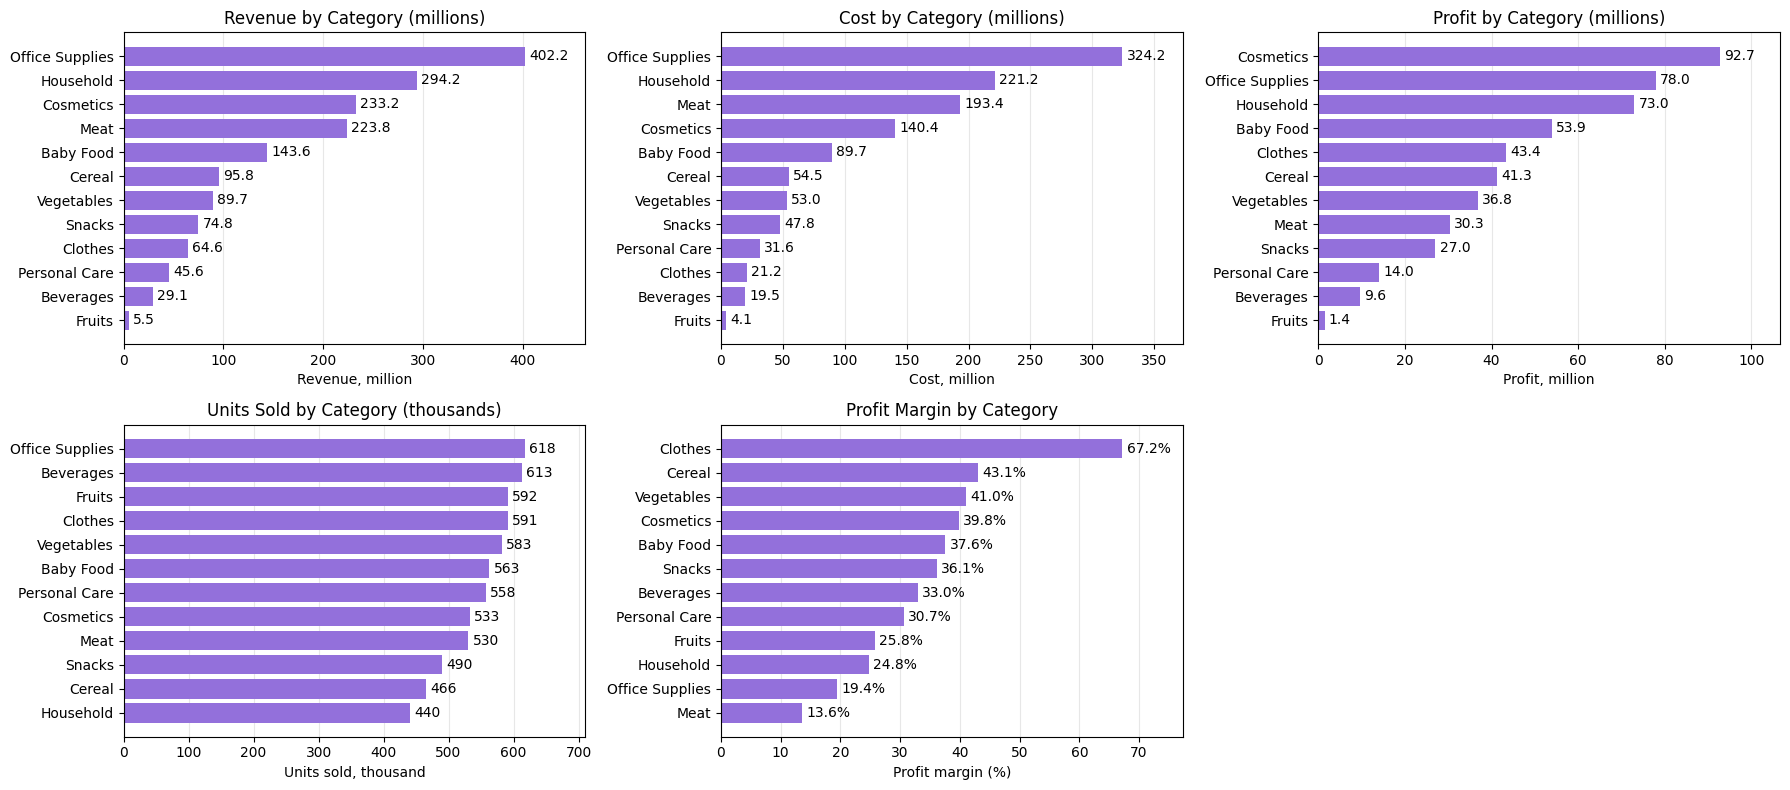

In [ ]:
# Обчислюємо рентабельність для кожної категорії
# Рентабельність = прибуток / дохід * 100%
category_sales["margin_pct"] = (
    category_sales["profit"] / category_sales["revenue"] * 100
)

# Готуємо дані для п'яти графіків
category_revenue = category_sales.sort_values("revenue")
category_cost = category_sales.sort_values("cost")
category_profit = category_sales.sort_values("profit")
category_units = category_sales.sort_values("units_sold")
category_margin = category_sales.sort_values("margin_pct")

# Створюємо фігуру: 3 графіки в першому рядку, 2 — у другому
fig, axes = plt.subplots(2, 3, figsize=(18, 8))


# Графік № 1. Дохід за категоріями

# Переводимо дохід у мільйони
category_revenue_millions = category_revenue["revenue"] / 1_000_000

bars = axes[0, 0].barh(
    category_revenue["item_type"],
    category_revenue_millions,
    color="#9370DB"
)

axes[0, 0].set_title("Revenue by Category (millions)")
axes[0, 0].set_xlabel("Revenue, million")
axes[0, 0].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 0].set_xlim(right=category_revenue_millions.max() * 1.15)


# Графік № 2. Витрати за категоріями

# Переводимо витрати у мільйони
category_cost_millions = category_cost["cost"] / 1_000_000

bars = axes[0, 1].barh(
    category_cost["item_type"],
    category_cost_millions,
    color="#9370DB"
)

axes[0, 1].set_title("Cost by Category (millions)")
axes[0, 1].set_xlabel("Cost, million")
axes[0, 1].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 1].set_xlim(right=category_cost_millions.max() * 1.15)


# Графік № 3. Прибуток за категоріями

# Переводимо прибуток у мільйони
category_profit_millions = category_profit["profit"] / 1_000_000

bars = axes[0, 2].barh(
    category_profit["item_type"],
    category_profit_millions,
    color="#9370DB"
)

axes[0, 2].set_title("Profit by Category (millions)")
axes[0, 2].set_xlabel("Profit, million")
axes[0, 2].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 2].set_xlim(right=category_profit_millions.max() * 1.15)


# Графік № 4. Кількість проданих одиниць за категоріями

# Переводимо кількість проданих одиниць у тисячі
category_units_thousands = category_units["units_sold"] / 1_000

bars = axes[1, 0].barh(
    category_units["item_type"],
    category_units_thousands,
    color="#9370DB"
)

axes[1, 0].set_title("Units Sold by Category (thousands)")
axes[1, 0].set_xlabel("Units sold, thousand")
axes[1, 0].bar_label(bars, fmt="%.0f", padding=3)
axes[1, 0].set_xlim(right=category_units_thousands.max() * 1.15)


# Графік № 5. Рентабельність за категоріями

bars = axes[1, 1].barh(
    category_margin["item_type"],
    category_margin["margin_pct"],
    color="#9370DB"
)

axes[1, 1].set_title("Profit Margin by Category")
axes[1, 1].set_xlabel("Profit margin (%)")

# Додаємо відсоткові значення біля стовпчиків
margin_labels = [
    f"{value:.1f}%"
    for value in category_margin["margin_pct"]
]
axes[1, 1].bar_label(
    bars,
    labels=margin_labels,
    padding=3
)

# Залишаємо місце праворуч для підписів
axes[1, 1].set_xlim(
    right=category_margin["margin_pct"].max() * 1.15
)


# Вимикаємо шосту, невикористану область
axes[1, 2].axis("off")


# Додаємо горизонтальну сітку для зручності порівняння
# та розміщуємо її за стовпчиками, а не поверх них
for ax in [axes[0, 0], axes[0, 1], axes[0, 2],
           axes[1, 0], axes[1, 1]]:
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=10)

# Автоматично налаштовуємо відступи між графіками
plt.tight_layout()
plt.show()

In [ ]:
# Обчислюємо прибуток на одну продану одиницю
# для кожної товарної категорії
category_sales["profit_per_unit"] = (
    category_sales["profit"] / category_sales["units_sold"]
)

# Виводимо категорії, рентабельність і прибуток на одиницю
display(
    category_sales[
        ["item_type", "margin_pct", "profit_per_unit"]
    ]
    .sort_values("profit_per_unit", ascending=False)
    .round(2)
)

,item_type,margin_pct,profit_per_unit
4,Cosmetics,39.77,173.87
6,Household,24.8,165.73
8,Office Supplies,19.39,126.25
0,Baby Food,37.55,95.86
2,Cereal,43.07,88.59
3,Clothes,67.2,73.44
11,Vegetables,40.98,63.13
7,Meat,13.56,57.2
10,Snacks,36.14,55.14
9,Personal Care,30.66,25.06


### Підсумок

Аналіз показав відмінності між товарними категоріями за обсягом продажів, доходом, прибутком і рентабельністю. Office Supplies має найбільший дохід (402,2 млн), найбільшу кількість проданих одиниць (618 тис.) і найбільші витрати (324,2 млн). Водночас за загальним прибутком ця категорія посідає друге місце (78 млн), а її рентабельність становить 19,4% — нижче за загальний показник компанії (29,46%).

Найвищу рентабельність має Clothes (67,2%), тоді як найбільший загальний прибуток (92,7 млн) і найбільший прибуток на одну продану одиницю (173,87) забезпечує Cosmetics. Найнижчу рентабельність зафіксовано в категорії Meat (13,56%).

Fruits посідає третє місце за кількістю проданих одиниць (592 тис.), але має найменші дохід (5,5 млн) і прибуток (1,4 млн). Прибуток на одну продану одиницю становить 2,41, що є найнижчим показником серед усіх категорій.

Отже, результати демонструють, що найбільший обсяг продажів і дохід не обов’язково означають найвищу рентабельність або найбільший прибуток на одиницю товару. Категорії відрізняються як масштабом продажів, так і фінансовою ефективністю.

## 3.4. Аналіз продажів за географією.
Під час географічного аналізу записи з невідомою країною (Unknown) виключено з порівняльних графіків за країнами та регіонами. Оскільки невідомо, скільки країн представлено в цій групі, її показники не можна коректно інтерпретувати як показники окремої географічної одиниці. Водночас записи збережено в основному наборі даних, а пропуски враховано як обмеження аналізу.

In [ ]:
# Продажі за країнами

country_sales = sales_data.groupby(
    "country",
    as_index=False
).agg(
    orders=("order_id", "nunique"),
    units_sold=("units_sold", "sum"),
    revenue=("revenue", "sum"),
    cost=("cost", "sum"),
    profit=("profit", "sum")
)

# Виключаємо невідомі країни лише для візуалізації
country_sales_plot = country_sales[
    country_sales["country"] != "Unknown"
].copy()

display(country_sales_plot.head().round(2))

,country,orders,units_sold,revenue,cost,profit
0,Albania,21,90608,32224853.87,21734147.85,10490706.02
1,Andorra,40,185686,47756693.17,32346656.54,15410036.63
2,Armenia,29,150665,37519840.21,28097487.03,9422353.18
3,Austria,28,145573,35740871.49,25713361.85,10027509.64
4,Belarus,28,153432,34236260.77,22383839.72,11852421.05


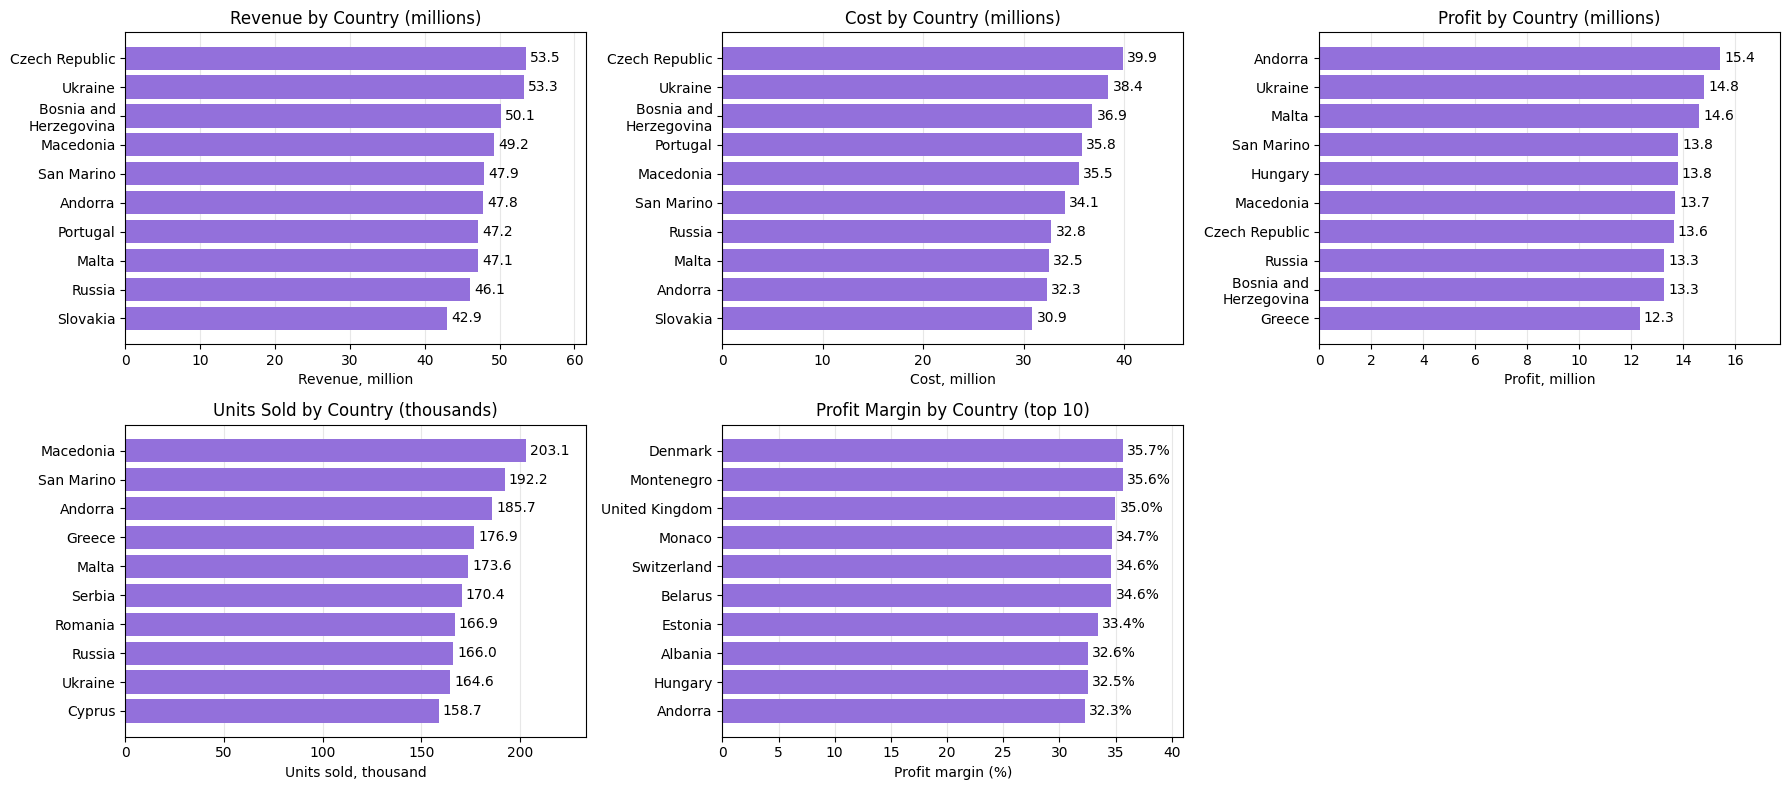

In [ ]:
# Готуємо дані для п'яти графіків

# Топ-10 країн за кожним абсолютним показником
country_revenue = country_sales_plot.sort_values(
    "revenue", ascending=False
).head(10)

country_cost = country_sales_plot.sort_values(
    "cost", ascending=False
).head(10)

country_profit = country_sales_plot.sort_values(
    "profit", ascending=False
).head(10)

country_units = country_sales_plot.sort_values(
    "units_sold", ascending=False
).head(10)

# Розраховуємо рентабельність для всіх відомих країн
# Рентабельність = прибуток / дохід * 100%
country_profitability = country_sales_plot.copy()

country_profitability["margin_pct"] = (
    country_profitability["profit"]
    / country_profitability["revenue"]
    * 100
)

# Відбираємо 10 країн із найвищою рентабельністю
country_margin = country_profitability.sort_values(
    "margin_pct", ascending=False
).head(10)


# Створюємо фігуру з 6 областями:
# 3 графіки в першому рядку та 3 — у другому
fig, axes = plt.subplots(2, 3, figsize=(18, 8))


# Графік № 1. Дохід за країнами

# Переводимо дохід у мільйони
country_revenue_millions = country_revenue["revenue"] / 1_000_000

bars = axes[0, 0].barh(
    country_revenue["country"].replace({
    "Bosnia and Herzegovina": "Bosnia and\nHerzegovina"
}),
    country_revenue_millions,
    color="#9370DB"
)

axes[0, 0].set_title("Revenue by Country (millions)")
axes[0, 0].set_xlabel("Revenue, million")
axes[0, 0].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 0].set_xlim(right=country_revenue_millions.max() * 1.15)

# Найбільше значення показуємо зверху
axes[0, 0].invert_yaxis()


# Графік № 2. Витрати за країнами

# Переводимо витрати у мільйони
country_cost_millions = country_cost["cost"] / 1_000_000

bars = axes[0, 1].barh(
    country_cost["country"].replace({
    "Bosnia and Herzegovina": "Bosnia and\nHerzegovina"
}),
    country_cost_millions,
    color="#9370DB"
)

axes[0, 1].set_title("Cost by Country (millions)")
axes[0, 1].set_xlabel("Cost, million")
axes[0, 1].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 1].set_xlim(right=country_cost_millions.max() * 1.15)
axes[0, 1].invert_yaxis()


# Графік № 3. Прибуток за країнами

# Переводимо прибуток у мільйони
country_profit_millions = country_profit["profit"] / 1_000_000

bars = axes[0, 2].barh(
    country_profit["country"].replace({
    "Bosnia and Herzegovina": "Bosnia and\nHerzegovina"
}),
    country_profit_millions,
    color="#9370DB"
)

axes[0, 2].set_title("Profit by Country (millions)")
axes[0, 2].set_xlabel("Profit, million")
axes[0, 2].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 2].set_xlim(right=country_profit_millions.max() * 1.15)
axes[0, 2].invert_yaxis()


# Графік № 4. Кількість проданих одиниць за країнами

# Переводимо кількість проданих одиниць у тисячі
country_units_thousands = country_units["units_sold"] / 1_000

bars = axes[1, 0].barh(
    country_units["country"].replace({
    "Bosnia and Herzegovina": "Bosnia and\nHerzegovina"
}),
    country_units_thousands,
    color="#9370DB"
)

axes[1, 0].set_title("Units Sold by Country (thousands)")
axes[1, 0].set_xlabel("Units sold, thousand")
axes[1, 0].bar_label(bars, fmt="%.1f", padding=3)
axes[1, 0].set_xlim(right=country_units_thousands.max() * 1.15)
axes[1, 0].invert_yaxis()


# Графік № 5. Рентабельність за країнами

bars = axes[1, 1].barh(
    country_margin["country"].replace({
    "Bosnia and Herzegovina": "Bosnia and\nHerzegovina"
}),
    country_margin["margin_pct"],
    color="#9370DB"
)

axes[1, 1].set_title("Profit Margin by Country (top 10)")
axes[1, 1].set_xlabel("Profit margin (%)")

# Показуємо відсоток біля кожного стовпчика
margin_labels = [
    f"{value:.1f}%"
    for value in country_margin["margin_pct"]
]

axes[1, 1].bar_label(
    bars,
    labels=margin_labels,
    padding=3
)

axes[1, 1].set_xlim(
    right=country_margin["margin_pct"].max() * 1.15
)
axes[1, 1].invert_yaxis()


# Вимикаємо шосту, невикористану область
axes[1, 2].axis("off")


# Додаємо вертикальні сітки для зручності порівняння
for ax in [axes[0, 0], axes[0, 1], axes[0, 2],
           axes[1, 0], axes[1, 1]]:
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=10)

# Налаштовуємо відступи між графіками
plt.tight_layout()
plt.show()

In [ ]:
# Формуємо таблицю показників топ-10 країн за рентабельністю
top_10_country_margin_display = country_margin[
    [
        "country",
        "revenue",
        "cost",
        "profit",
        "units_sold",
        "margin_pct"
    ]
].copy()

# Переводимо дохід, витрати та прибуток у мільйони
top_10_country_margin_display[
    ["revenue", "cost", "profit"]
] /= 1_000_000

# Переводимо кількість проданих одиниць у тисячі
top_10_country_margin_display["units_sold"] /= 1_000

# Уточнюємо назви стовпців для зрозумілого відображення
top_10_country_margin_display = (
    top_10_country_margin_display
    .rename(columns={
        "revenue": "revenue_millions",
        "cost": "cost_millions",
        "profit": "profit_millions",
        "units_sold": "units_sold_thousands"
    })
    .round(2)
)

# Виводимо таблицю для порівняння показників країн
display(top_10_country_margin_display)

,country,revenue_millions,cost_millions,profit_millions,units_sold_thousands,margin_pct
11,Denmark,26.97,17.35,9.62,127.36,35.66
29,Montenegro,31.35,20.18,11.17,137.2,35.63
44,United Kingdom,26.65,17.33,9.33,115.78,34.99
28,Monaco,13.83,9.03,4.8,53.42,34.69
42,Switzerland,31.88,20.84,11.04,144.32,34.63
4,Belarus,34.24,22.38,11.85,153.43,34.62
12,Estonia,23.41,15.58,7.83,126.23,33.44
0,Albania,32.22,21.73,10.49,90.61,32.55
18,Hungary,42.41,28.62,13.79,152.24,32.51
1,Andorra,47.76,32.35,15.41,185.69,32.27


### Підсумок

Проведено аналіз доходу, витрат, прибутку, кількості проданих одиниць і рентабельності за країнами.

Серед країн із відомими назвами найбільший дохід зафіксовано в Чехії (53,5 млн), найбільший прибуток — в Андоррі (15,4 млн), а найбільшу кількість проданих одиниць — у Македонії (203,1 тис.). Це свідчить про те, що країна з найбільшим обсягом продажів не обов'язково забезпечує найбільший дохід або прибуток.

Додатковий аналіз рентабельності показав, що найвищий показник має Данія (35,7%), за нею йдуть Чорногорія (35,6%) та Велика Британія (35%). Склад країн із найвищою рентабельністю відрізняється від рейтингів за абсолютними фінансовими показниками. Водночас Андорра поєднує значний абсолютний прибуток із рентабельністю 32,3%, що також входить до десяти найвищих показників серед досліджуваних країн.

Отже, аналіз показав, що країни відрізняються не лише масштабом продажів і величиною прибутку, а й рентабельністю. Тому для комплексної оцінки результатів необхідно враховувати як абсолютні фінансові показники, так і частку прибутку в доході.

In [ ]:
# Продажі за регіонами
region_sales = sales_data.groupby(
    "region",
    as_index=False
).agg(
    orders=("order_id", "nunique"),
    units_sold=("units_sold", "sum"),
    revenue=("revenue", "sum"),
    cost=("cost", "sum"),
    profit=("profit", "sum")
)

# Виключаємо невідомий регіон лише для візуалізації
region_sales_plot = region_sales[
    region_sales["region"] != "Unknown"
].copy()

display(region_sales_plot.round(2))

,region,orders,units_sold,revenue,cost,profit
0,Asia,82,410427,93330887.37,68178634.42,25152252.95
1,Europe,1164,5761244,1505652873.89,1057096091.78,448556782.11


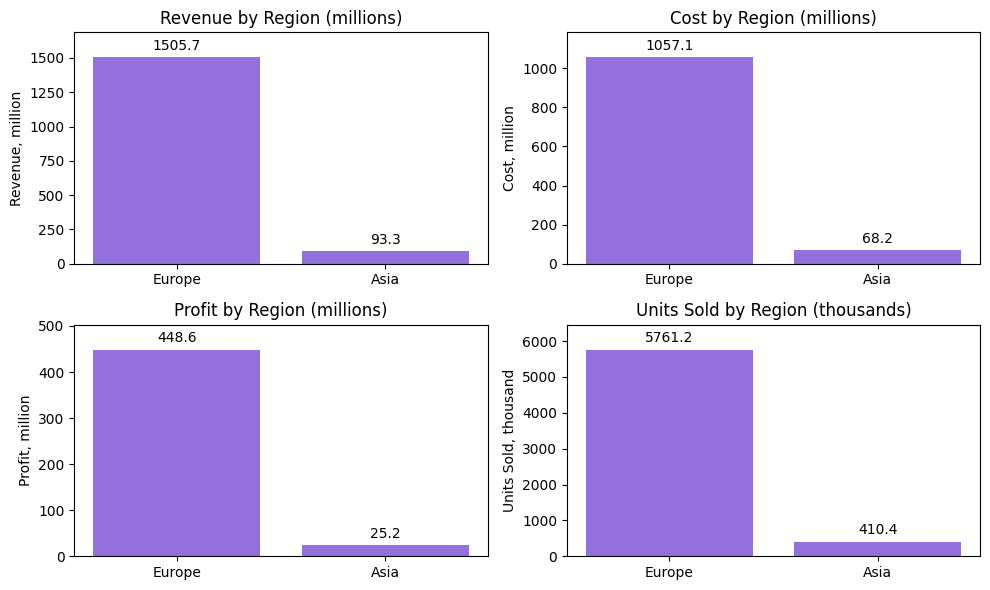

In [ ]:
# Створюємо одне вікно з чотирма графіками
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

# Готуємо дані для чотирьох графіків
region_revenue = region_sales_plot.sort_values("revenue", ascending=False)
region_cost = region_sales_plot.sort_values("cost", ascending=False)
region_profit = region_sales_plot.sort_values("profit", ascending=False)
region_units = region_sales_plot.sort_values("units_sold", ascending=False)

# Графік № 1. Дохід за регіонами
revenue_millions = region_revenue["revenue"] / 1_000_000
bars = axes[0, 0].bar(
    region_revenue["region"],
    revenue_millions,
    color="#9370DB"
)
axes[0, 0].set_title("Revenue by Region (millions)")
axes[0, 0].set_ylabel("Revenue, million")
axes[0, 0].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 0].set_ylim(top=revenue_millions.max() * 1.12)

# Графік № 2. Витрати за регіонами
cost_millions = region_cost["cost"] / 1_000_000
bars = axes[0, 1].bar(
    region_cost["region"],
    cost_millions,
    color="#9370DB"
)
axes[0, 1].set_title("Cost by Region (millions)")
axes[0, 1].set_ylabel("Cost, million")
axes[0, 1].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 1].set_ylim(top=cost_millions.max() * 1.12)

# Графік № 3. Прибуток за регіонами
profit_millions = region_profit["profit"] / 1_000_000
bars = axes[1, 0].bar(
    region_profit["region"],
    profit_millions,
    color="#9370DB"
)
axes[1, 0].set_title("Profit by Region (millions)")
axes[1, 0].set_ylabel("Profit, million")
axes[1, 0].bar_label(bars, fmt="%.1f", padding=3)
axes[1, 0].set_ylim(top=profit_millions.max() * 1.12)

# Графік № 4. Кількість проданих одиниць за регіонами
units_thousands = region_units["units_sold"] / 1_000
bars = axes[1, 1].bar(
    region_units["region"],
    units_thousands,
    color="#9370DB"
)
axes[1, 1].set_title("Units Sold by Region (thousands)")
axes[1, 1].set_ylabel("Units Sold, thousand")
axes[1, 1].bar_label(bars, fmt="%.1f", padding=3)
axes[1, 1].set_ylim(top=units_thousands.max() * 1.12)

# Налаштовуємо підписи та відстані між графіками
for ax in axes.flat:
    ax.tick_params(axis="x", labelrotation=0)

plt.tight_layout()
plt.show()


In [ ]:
# Отримуємо точний дохід Європи
europe_revenue = region_sales.loc[
    region_sales["region"] == "Europe",
    "revenue"
].iloc[0]

# Обчислюємо частку Європи від загального доходу компанії
europe_share = europe_revenue / total_revenue * 100

# Виводимо результат з округленням до одного знака після коми
print(f"Частка Європи від загального доходу: {europe_share:.1f}%")

Частка Європи від загального доходу: 88.5%


### Підсумок

Європа значно випереджає Азію за кількістю замовлень, проданих одиниць, доходом, витратами та прибутком. Дохід Європи становить 1 505,7 млн, а прибуток — 448,6 млн. Для порівняння, в Азії дохід становить 93,3 млн, а прибуток — 25,2 млн.

На Європу припадає **88,5% загального доходу компанії** (1 505,7 млн із 1 702,13 млн). Цю частку розраховано від загального доходу за всіма записами, включно з 82 замовленнями, для яких країну не визначено (`Unknown`).

Отже, Європа є основним регіоном продажів і прибутку компанії.

## 3.5. Аналіз продажів за каналами (онлайн або офлайн)

In [ ]:
# Продажі за каналами
channel_sales = sales_data.groupby(
    "sales_channel",
    as_index=False
).agg(
    orders=("order_id", "nunique"),
    units_sold=("units_sold", "sum"),
    revenue=("revenue", "sum"),
    cost=("cost", "sum"),
    profit=("profit", "sum")
)

display(channel_sales.round(2))

,sales_channel,orders,units_sold,revenue,cost,profit
0,offline,665,3320363,871760623.88,618294105.07,253466518.81
1,online,663,3256161,830368784.33,582400844.14,247967940.19


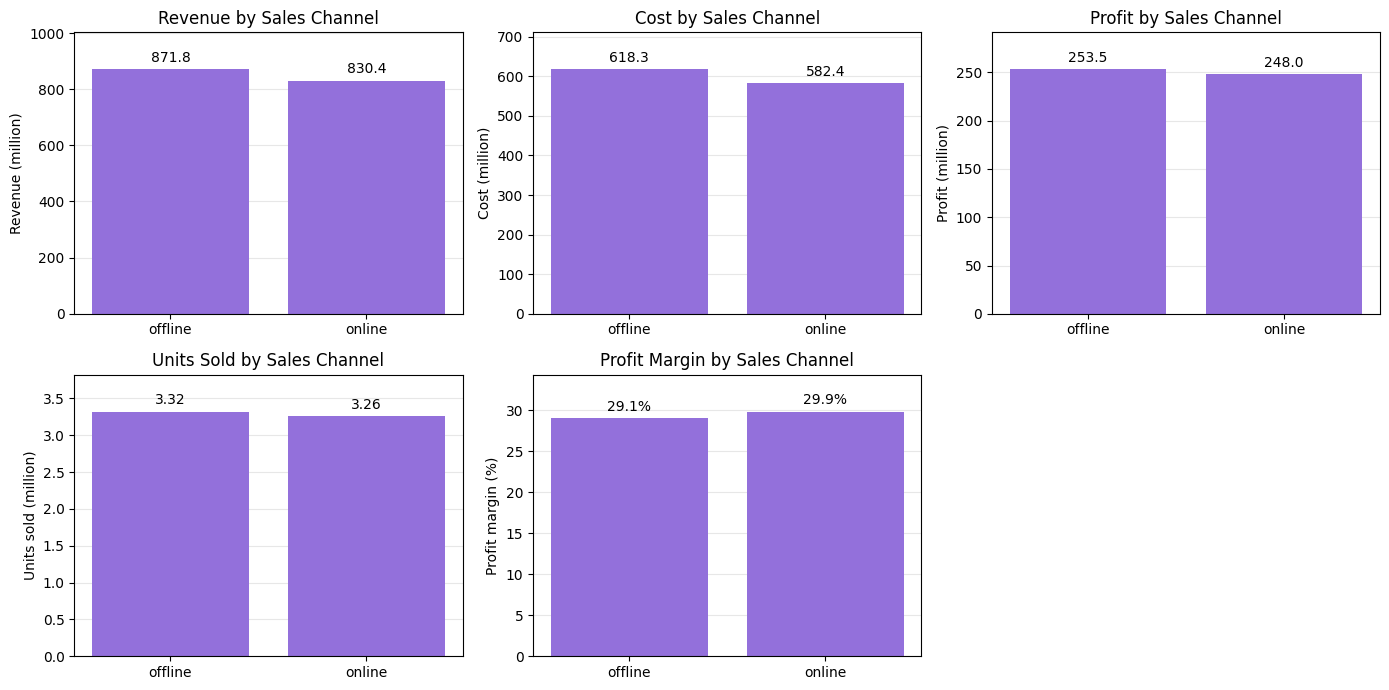

In [ ]:
# Обчислюємо рентабельність продажів для кожного каналу
# Рентабельність = прибуток / дохід * 100%
channel_sales["margin_pct"] = (
    channel_sales["profit"] / channel_sales["revenue"] * 100
)

# Створюємо фігуру з 6 областями: 3 у першому рядку та 3 у другому
fig, axes = plt.subplots(2, 3, figsize=(14, 7))


# Графік № 1. Дохід за каналами продажів

# Переводимо дохід у мільйони
revenue_millions = channel_sales["revenue"] / 1_000_000

bars = axes[0, 0].bar(
    channel_sales["sales_channel"],
    revenue_millions,
    color="#9370DB"
)

axes[0, 0].set_title("Revenue by Sales Channel")
axes[0, 0].set_ylabel("Revenue (million)")
axes[0, 0].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 0].set_ylim(top=revenue_millions.max() * 1.15)


# Графік № 2. Витрати за каналами продажів

# Переводимо витрати у мільйони
cost_millions = channel_sales["cost"] / 1_000_000

bars = axes[0, 1].bar(
    channel_sales["sales_channel"],
    cost_millions,
    color="#9370DB"
)

axes[0, 1].set_title("Cost by Sales Channel")
axes[0, 1].set_ylabel("Cost (million)")
axes[0, 1].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 1].set_ylim(top=cost_millions.max() * 1.15)


# Графік № 3. Прибуток за каналами продажів

# Переводимо прибуток у мільйони
profit_millions = channel_sales["profit"] / 1_000_000

bars = axes[0, 2].bar(
    channel_sales["sales_channel"],
    profit_millions,
    color="#9370DB"
)

axes[0, 2].set_title("Profit by Sales Channel")
axes[0, 2].set_ylabel("Profit (million)")
axes[0, 2].bar_label(bars, fmt="%.1f", padding=3)
axes[0, 2].set_ylim(top=profit_millions.max() * 1.15)


# Графік № 4. Кількість проданих одиниць за каналами

# Переводимо кількість проданих одиниць у мільйони
units_millions = channel_sales["units_sold"] / 1_000_000

bars = axes[1, 0].bar(
    channel_sales["sales_channel"],
    units_millions,
    color="#9370DB"
)

axes[1, 0].set_title("Units Sold by Sales Channel")
axes[1, 0].set_ylabel("Units sold (million)")
axes[1, 0].bar_label(bars, fmt="%.2f", padding=3)
axes[1, 0].set_ylim(top=units_millions.max() * 1.15)


# Графік № 5. Рентабельність за каналами продажів

bars = axes[1, 1].bar(
    channel_sales["sales_channel"],
    channel_sales["margin_pct"],
    color="#9370DB"
)

axes[1, 1].set_title("Profit Margin by Sales Channel")
axes[1, 1].set_ylabel("Profit margin (%)")

# Додаємо підписи рентабельності над стовпчиками
margin_labels = [
    f"{value:.1f}%"
    for value in channel_sales["margin_pct"]
]
axes[1, 1].bar_label(bars, labels=margin_labels, padding=3)

# Залишаємо місце над стовпчиками для підписів
axes[1, 1].set_ylim(
    top=channel_sales["margin_pct"].max() * 1.15
)


# Вимикаємо шосту, невикористану область
axes[1, 2].axis("off")

# Додаємо горизонтальну сітку на всіх п'яти графіках
for ax in [axes[0, 0], axes[0, 1], axes[0, 2],
           axes[1, 0], axes[1, 1]]:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

# Налаштовуємо відступи та показуємо фігуру
plt.tight_layout()
plt.show()

### Підсумок

Офлайн-канал має дещо вищі абсолютні показники продажів: за майже однакової кількості замовлень він забезпечує більший дохід (872 млн проти 830 млн) і прибуток (253 млн проти 248 млн), ніж онлайн-канал. Водночас рентабельність онлайн-продажів становить 29,9%, що трохи вище за показник офлайн-каналу (29,1%).

Отже, результати каналів близькі за масштабом продажів і загальним прибутком, але відрізняються за рентабельністю: офлайн забезпечує дещо більші абсолютні фінансові результати, тоді як онлайн ефективніше перетворює дохід на прибуток.

## 3.6. Аналіз інтервалу часу між замовленням та його відвантаженням

In [ ]:
# Додаємо до sales_data новий стовпець shipping_days — кількість днів між замовленням і відвантаженням.
sales_data["shipping_days"] = (
    sales_data["ship_date"] - sales_data["order_date"]
).dt.days

display(
    sales_data[[
        "order_date",
        "ship_date",
        "shipping_days"
    ]].head()
)

,order_date,ship_date,shipping_days
0,2014-10-08,2014-10-18,10
1,2016-08-11,2016-08-11,0
2,2014-07-18,2014-08-11,24
3,2017-05-13,2017-06-13,31
4,2012-08-11,2012-09-18,38


In [ ]:
sales_data["shipping_days"].describe()

,shipping_days
count,1328.000000
mean,24.786898
std,14.586041
min,0.000000
25%,12.000000
50%,25.000000
75%,37.000000
max,50.000000


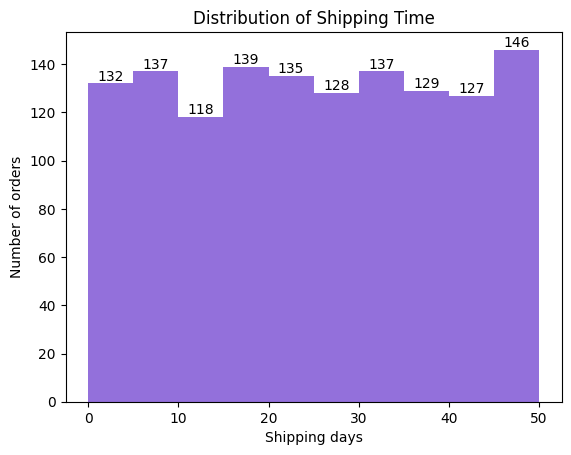

In [ ]:
# Будуємо гістограму, щоб побачити, як розподіляються інтервали відвантаження

n, bins, patches = plt.hist(sales_data["shipping_days"], color="#9370DB")

plt.xlabel("Shipping days")
plt.ylabel("Number of orders")
plt.title("Distribution of Shipping Time")

for i in range(len(n)):
    plt.text(
        (bins[i] + bins[i + 1]) / 2,
        n[i],
        int(n[i]),
        ha="center",
        va="bottom"
    )

plt.show()

- Розподіл досить рівномірний: у кожному інтервалі приблизно 118–146 замовлень.

- Найбільше замовлень — 146 — потрапило в інтервал 45–50 днів.

- Найменше — 118 — в інтервал 10–15 днів.

- Не видно різкого зосередження замовлень лише в коротких або лише в довгих інтервалах.

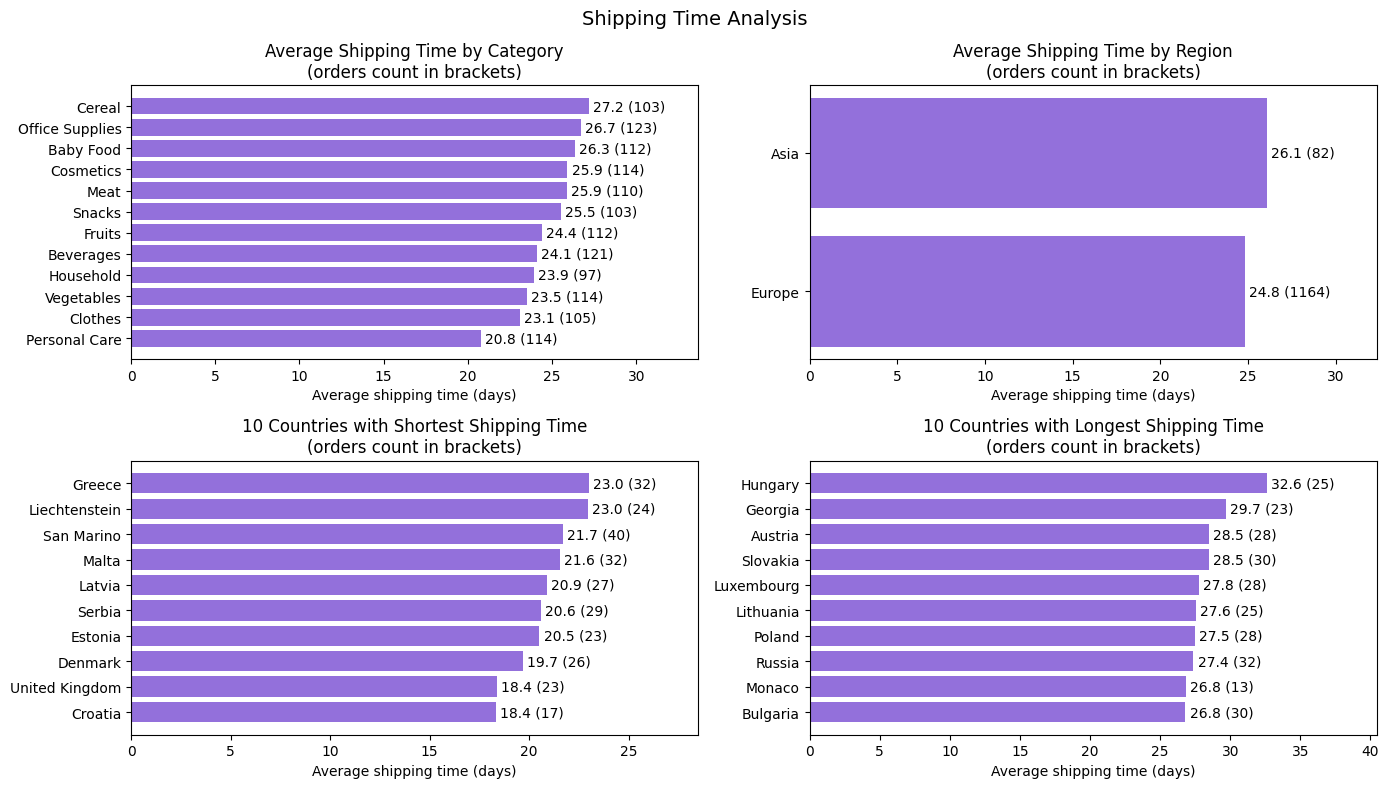

In [ ]:
# Середній час відвантаження та кількість замовлень за категоріями
category_shipping = (
    sales_data.groupby("item_type")["shipping_days"]
    .agg(["mean", "count"])
    .sort_values("mean")
)

# Середній час відвантаження та кількість замовлень за регіонами
region_shipping = (
    sales_data[sales_data["region"] != "Unknown"]
    .groupby("region")["shipping_days"]
    .agg(["mean", "count"])
    .sort_values("mean")
)

# Середній час відвантаження та кількість замовлень за країнами
country_shipping = (
    sales_data[sales_data["country"] != "Unknown"]
    .groupby("country")["shipping_days"]
    .agg(["mean", "count"])
)

fastest_countries = (
    country_shipping.nsmallest(10, "mean")
    .sort_values("mean")
)

slowest_countries = (
    country_shipping.nlargest(10, "mean")
    .sort_values("mean")
)

# Створюємо масив із чотирьох графіків
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Графік №1. Товарні категорії
bars = axes[0, 0].barh(
    category_shipping.index,
    category_shipping["mean"],
    color="#9370DB"
)
axes[0, 0].set_title(
    "Average Shipping Time by Category\n(orders count in brackets)"
)
axes[0, 0].set_xlabel("Average shipping time (days)")

labels = [
    f"{mean:.1f} ({count})"
    for mean, count in zip(
        category_shipping["mean"],
        category_shipping["count"]
    )
]
axes[0, 0].bar_label(bars, labels=labels, padding=3, fontsize=10)

# Графік №2. Регіони
bars = axes[0, 1].barh(
    region_shipping.index,
    region_shipping["mean"],
    color="#9370DB"
)
axes[0, 1].set_title(
    "Average Shipping Time by Region\n(orders count in brackets)"
)
axes[0, 1].set_xlabel("Average shipping time (days)")

labels = [
    f"{mean:.1f} ({count})"
    for mean, count in zip(
        region_shipping["mean"],
        region_shipping["count"]
    )
]
axes[0, 1].bar_label(bars, labels=labels, padding=3, fontsize=10)

# Графік №3. Країни з найкоротшим середнім часом
bars = axes[1, 0].barh(
    fastest_countries.index,
    fastest_countries["mean"],
    color="#9370DB"
)
axes[1, 0].set_title(
    "10 Countries with Shortest Shipping Time\n(orders count in brackets)"
)
axes[1, 0].set_xlabel("Average shipping time (days)")

labels = [
    f"{mean:.1f} ({count})"
    for mean, count in zip(
        fastest_countries["mean"],
        fastest_countries["count"]
    )
]
axes[1, 0].bar_label(bars, labels=labels, padding=3, fontsize=10)

# Графік №4. Країни з найдовшим середнім часом
bars = axes[1, 1].barh(
    slowest_countries.index,
    slowest_countries["mean"],
    color="#9370DB"
)
axes[1, 1].set_title(
    "10 Countries with Longest Shipping Time\n(orders count in brackets)"
)
axes[1, 1].set_xlabel("Average shipping time (days)")

labels = [
    f"{mean:.1f} ({count})"
    for mean, count in zip(
        slowest_countries["mean"],
        slowest_countries["count"]
    )
]
axes[1, 1].bar_label(bars, labels=labels, padding=3, fontsize=10)

# Залишаємо місце праворуч для підписів
for ax in axes.flat:
    ax.set_xlim(right=ax.get_xlim()[1] * 1.18)

fig.suptitle("Shipping Time Analysis", fontsize=14)
plt.tight_layout()
plt.show()


### Підсумок

Аналіз показав відмінності в середньому часі відвантаження між країнами, регіонами та товарними категоріями. Серед країн найкоротший середній час зафіксовано в Хорватії — 18,4 дня на основі 17 замовлень, а найдовший — в Угорщині, 32,6 дня на основі 25 замовлень. Серед категорій найкоротший середній час має Personal Care (20,8 дня), а найдовший — Cereal (27,2 дня). У Європі середній час становить 24,8 дня, в Азії — 26,1 дня.

Водночас кількість замовлень у групах відрізняється, а в окремих країнах вона невелика. Тому виявлені відмінності слід розглядати як описові результати: вони можуть бути зумовлені випадковими коливаннями даних і самі по собі не підтверджують стійких відмінностей у тривалості відвантаження між групами.

## 3.7. Аналіз залежності прибутку від часу, необхідного на відвантаження товару

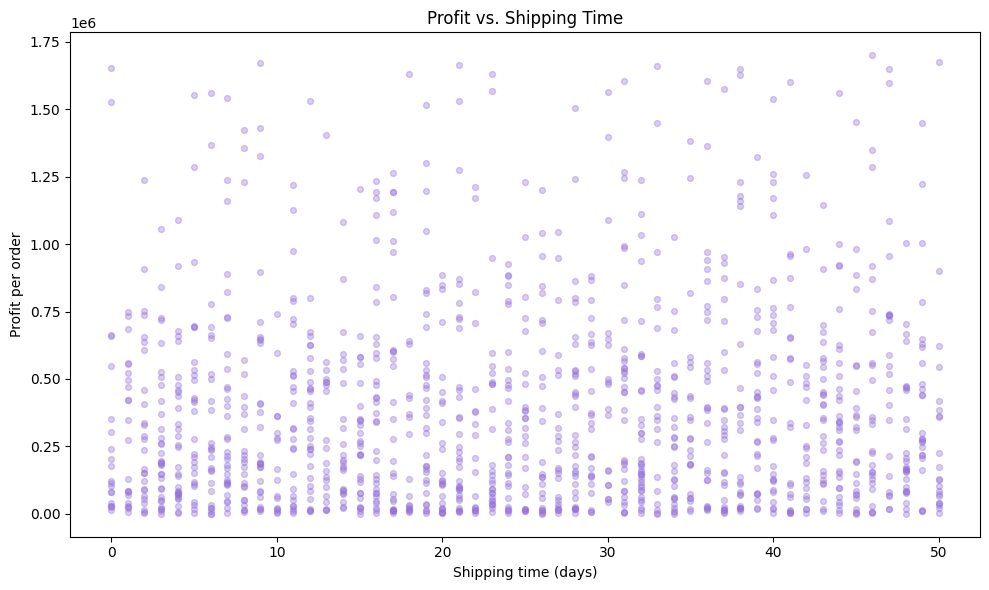

In [ ]:
# Залишаємо замовлення, для яких відомі обидва показники
plot_data = sales_data.dropna(
    subset=["shipping_days", "profit"]
)

# Будуємо точковий графік для окремих замовлень
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["shipping_days"],
    plot_data["profit"],
    color="#9370DB",
    alpha=0.35,
    s=18
)

plt.title("Profit vs. Shipping Time")
plt.xlabel("Shipping time (days)")
plt.ylabel("Profit per order")

plt.tight_layout()
plt.show()

**Підсумок**

Точковий графік показує розподіл прибутку залежно від часу відвантаження для окремих замовлень. Чіткої тенденції до збільшення або зменшення прибутку зі збільшенням часу відвантаження візуально не спостерігається. Більшість точок зосереджена в нижній частині діапазону прибутку, а замовлення з високим прибутком трапляються рідше.

Для кількісної оцінки зв’язку між показниками далі обчислимо коефіцієнти кореляції Пірсона та Спірмена.

In [ ]:
from scipy.stats import pearsonr, spearmanr

# Беремо рядки, у яких є обидва потрібні значення
correlation_data = sales_data[
    ["shipping_days", "profit"]
].dropna()

# Кореляція Пірсона
pearson_r, pearson_p = pearsonr(
    correlation_data["shipping_days"],
    correlation_data["profit"]
)

# Коефіцієнт детермінації R²
r_squared = pearson_r ** 2

# Кореляція Спірмена
spearman_rho, spearman_p = spearmanr(
    correlation_data["shipping_days"],
    correlation_data["profit"]
)

# Виводимо результати
print(f"Number of orders: {len(correlation_data)}")
print(f"Pearson correlation (r): {pearson_r:.4f}")
print(f"R²: {r_squared:.2%}")
print(f"Pearson p-value: {pearson_p:.4g}")
print(f"Spearman correlation (rho): {spearman_rho:.4f}")
print(f"Spearman p-value: {spearman_p:.4g}")

Number of orders: 1328
Pearson correlation (r): 0.0603
R²: 0.36%
Pearson p-value: 0.028
Spearman correlation (rho): 0.0581
Spearman p-value: 0.03418


Аналіз 1328 замовлень виявив дуже слабкий позитивний зв’язок між часом відвантаження та прибутком. Коефіцієнт кореляції Пірсона становив 0,0603 (R² = 0,36%, p-value = 0,028), а коефіцієнт Спірмена — 0,0581 (p-value = 0,03418). Обидва результати статистично значущі на рівні 5%, проте сила зв’язку є практично незначною. Тому на основі цього аналізу немає підстав стверджувати, що зміна часу відвантаження суттєво пов’язана зі зміною прибутку або що скорочення часу відвантаження саме по собі збільшить прибуток.

## 3.8. Аналіз динаміки продажів у часі

### 3.8.1. Загальна динаміка доходу

Досліджуємо зміну доходу компанії за місяцями та роками для визначення загальних тенденцій протягом досліджуваного періоду.

In [ ]:
print("Початкова дата:", sales_data["order_date"].min())
print("Кінцева дата:", sales_data["order_date"].max())

Початкова дата: 2010-01-01 00:00:00
Кінцева дата: 2017-07-23 00:00:00


In [ ]:
# Створюємо нову колонку order_month,
# яка містить рік і місяць оформлення замовлення
sales_data["order_month"] = (
    sales_data["order_date"].dt.to_period("M")
)
print(sales_data[["order_date", "order_month"]].head())

  order_date order_month
0 2014-10-08     2014-10
1 2016-08-11     2016-08
2 2014-07-18     2014-07
3 2017-05-13     2017-05
4 2012-08-11     2012-08


In [ ]:
# Залишаємо дані лише за повні роки — 2010–2016
sales_data_full_years = sales_data[
    sales_data["order_date"].dt.year <= 2016
].copy()

# Групуємо відфільтровані дані за місяцями
# та обчислюємо загальний дохід за кожен місяць
monthly_sales = sales_data_full_years.groupby(
    "order_month"
)["revenue"].sum()

# Переглядаємо перші п'ять результатів
monthly_sales.head()

,revenue
order_month,
2010-01,21115354.48
2010-02,19853023.2
2010-03,8474747.19
2010-04,10058016.05
2010-05,20304725.59


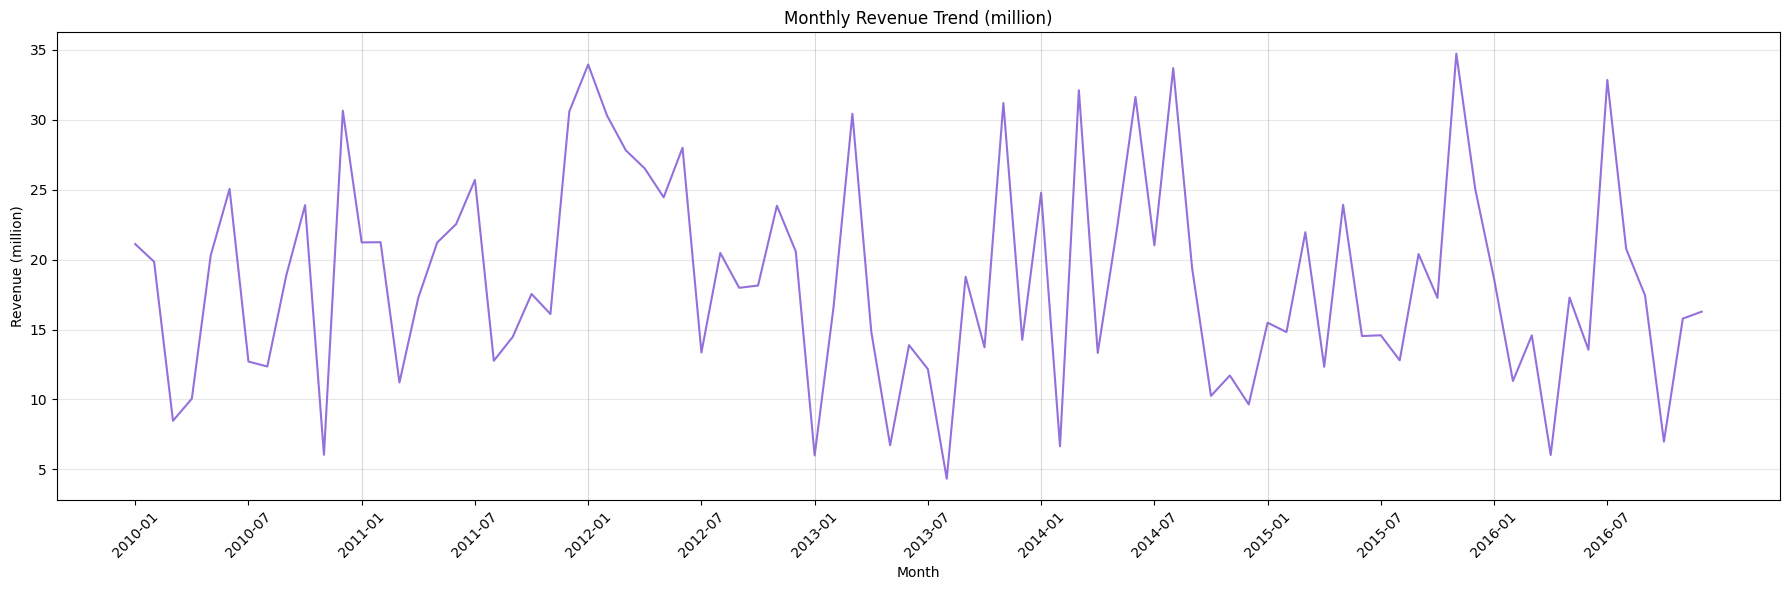

In [ ]:
plt.figure(figsize=(18, 6))

# Будуємо лінійний графік місячного доходу в мільйонах
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values / 1_000_000,
    color="#9370DB"
)

plt.title("Monthly Revenue Trend (million)")
plt.xlabel("Month")
plt.ylabel("Revenue (million)")

# Показуємо підписи осі X через кожні 6 місяців,
# щоб вони не накладалися один на одного
plt.xticks(
    ticks=range(0, len(monthly_sales), 6),
    labels=monthly_sales.index.astype(str)[::6],
    rotation=45
)
# Додаємо легку горизонтальну сітку
plt.grid(axis="y", alpha=0.3)

# Позначаємо вертикальними лініями межі років
for i in range(12, len(monthly_sales), 12):
    plt.axvline(i, color="gray", alpha=0.3, linewidth=0.8)

plt.tight_layout()
plt.show()

### Висновок за місячною динамікою доходу

Місячний дохід компанії протягом 2010–2016 років суттєво коливається: спостерігаються як різкі зростання, так і значні зниження. Лінійний графік дає змогу простежити короткострокові зміни доходу, однак для оцінки повторюваності коливань у певні календарні місяці потрібне окреме порівняння місячних показників за різні роки. Це питання розглянемо далі в межах дослідження сезонності продажів.

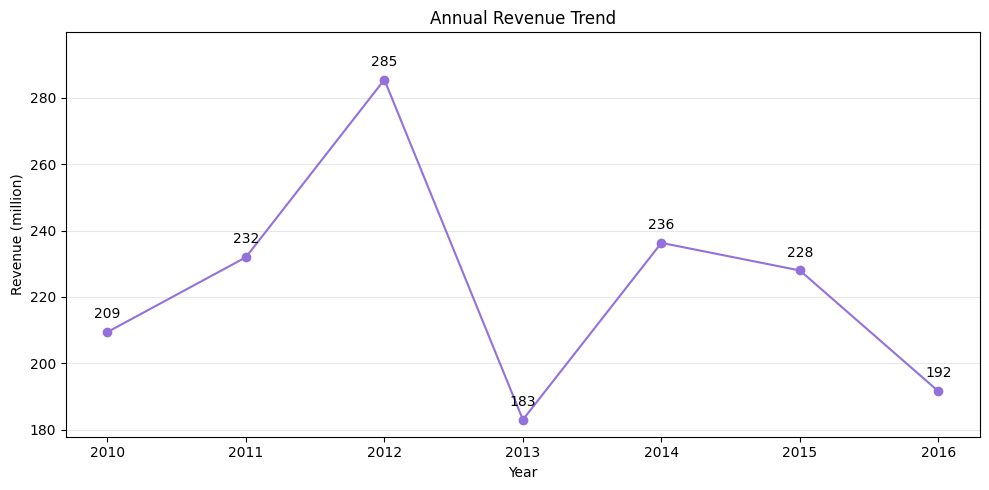

In [ ]:
# Створюємо колонку order_year з роком оформлення замовлення
# у таблиці, яка містить лише повні роки — 2010–2016
sales_data_full_years["order_year"] = (
    sales_data_full_years["order_date"].dt.year
)

# Групуємо дані за роками та обчислюємо загальний дохід за кожен рік
yearly_sales = sales_data_full_years.groupby(
    "order_year"
)["revenue"].sum()

# Створюємо полотно для графіка
plt.figure(figsize=(10, 5))

# Будуємо лінійний графік річного доходу в мільйонах
plt.plot(
    yearly_sales.index,
    yearly_sales.values / 1_000_000,
    marker="o",
    color="#9370DB"
)

# Додаємо заголовок і підписи осей
plt.title("Annual Revenue Trend")
plt.xlabel("Year")
plt.ylabel("Revenue (million)")

# Відображаємо всі роки на осі X та додаємо горизонтальну сітку
plt.xticks(yearly_sales.index)
plt.grid(axis="y", alpha=0.3)

# Додаємо підписи значень доходу над кожною точкою
for year, revenue in zip(
    yearly_sales.index,
    yearly_sales.values / 1_000_000
):
    plt.annotate(
        f"{revenue:.0f}",       # Округлюємо дохід до цілого числа
        (year, revenue),        # Координати точки, біля якої буде підпис
        textcoords="offset points",
        xytext=(0, 10),         # Зміщуємо підпис на 10 пунктів угору
        ha="center"             # Вирівнюємо підпис по центру точки
    )

# Залишаємо над найвищою точкою місце для підпису
plt.ylim(top=yearly_sales.max() / 1_000_000 * 1.05)

# Автоматично налаштовуємо відступи та показуємо графік
plt.tight_layout()
plt.show()

 **Висновок за річною динамікою доходу**

У 2010–2012 роках спостерігалося зростання доходу компанії. У 2013 році дохід помітно знизився, а у 2014 році відновилося зростання. Протягом 2015–2016 років дохід знову зменшувався.

Дані за 2017 рік охоплюють період лише до 23 липня, тому річний дохід за цей рік не можна коректно порівнювати з показниками повних років.

Отже, протягом досліджуваного періоду дохід компанії змінювався нерівномірно: періоди зростання чергувалися зі зниженнями.

### 3.8.2. Динаміка доходу за категоріями товарів

Аналізуємо зміну доходу за роками для різних категорій товарів, щоб визначити категорії з найбільшим доходом та основні тенденції його зміни.

In [ ]:
# Групуємо дані за роком і товарною категорією
# та обчислюємо сумарний дохід для кожної групи
category_yearly_sales = sales_data_full_years.groupby(
    ["order_year", "item_type"]
)["revenue"].sum()

# Виводимо отримані результати
print(category_yearly_sales)

order_year  item_type      
2010        Baby Food          18351313.36
            Beverages            3699296.9
            Cereal              17599280.6
            Clothes             7720304.16
            Cosmetics           25620357.2
                                  ...     
2016        Meat               21259880.88
            Office Supplies    43534690.92
            Personal Care       4998851.99
            Snacks              7413251.88
            Vegetables         14594411.92
Name: revenue, Length: 84, dtype: Float64


In [ ]:
# Перетворюємо згруповані дані на таблицю:
# рядки — роки, стовпці — категорії товарів
category_yearly_table = category_yearly_sales.unstack()

category_yearly_table

item_type,Baby Food,Beverages,Cereal,Clothes,Cosmetics,Fruits,Household,Meat,Office Supplies,Personal Care,Snacks,Vegetables
order_year,,,,,,,,,,,,
2010,18351313.36,3699296.9,17599280.6,7720304.16,25620357.2,701634.66,33551831.89,36099439.74,40776816.57,7094164.0,11739962.94,6427845.38
2011,14521092.24,3274050.0,15945864.0,7397709.6,39341879.2,883224.45,30088188.48,30471005.25,58527498.75,6690254.34,7315448.1,17481342.26
2012,28261538.24,3725014.8,12120872.5,12543267.68,56664180.4,524168.73,43688151.25,40162662.33,52324072.29,6018433.74,12734784.54,16718745.26
2013,18354887.28,3624136.1,15340488.9,4886783.04,14507607.6,768745.35,29934486.38,25896873.87,40862125.08,5355439.98,13632107.52,9798678.18
2014,26004097.2,2866929.0,11884111.8,11297912.8,30832655.6,694179.99,46085904.01,23268499.17,56529586.47,8869911.71,6047203.14,11904832.44
2015,19961109.04,4059300.05,12507999.9,5938275.2,20544902.4,563289.42,46133351.18,28157782.38,75447888.18,4435895.75,4591437.36,5612867.98
2016,12321599.76,4003166.7,9252591.7,12197177.92,18402622.4,1000642.5,42542068.2,21259880.88,43534690.92,4998851.99,7413251.88,14594411.92


In [ ]:
# Створюємо інтерактивний графік річного доходу з можливістю вибору категорії

# Імпортуємо інструменти для інтерактивного графіка
import ipywidgets as widgets
from IPython.display import display, clear_output

# Створюємо список категорій із назв колонок таблиці
categories = category_yearly_table.columns.tolist()

# Створюємо випадаючий список із назвами категорій
category_filter = widgets.Dropdown(
    options=categories,   # Список категорій для вибору
    value=categories[0],  # Встановлюємо першу категорію як початково вибрану
    description="Category:",  # Задаємо підпис біля списку
    layout=widgets.Layout(width="250px")  # Задаємо ширину випадаючого списку
)

# Створюємо окрему область для графіка
category_plot_output = widgets.Output(
    layout=widgets.Layout(width="750px")  # Задаємо ширину області для графіка
)

# Функція побудови та оновлення графіка
def update_category_chart(change=None):
    # Отримуємо вибрану категорію
    category = category_filter.value

    # Працюємо всередині області виведення графіка
    with category_plot_output:
        # Очищаємо попередній вивід
        clear_output(wait=True)

        # Створюємо графік доходу за роками
        fig, ax = plt.subplots(figsize=(9, 5))

        ax.plot(
            category_yearly_table.index,
            category_yearly_table[category] / 1_000_000,
            marker="o",
            color="#9370DB"
        )

        # Додаємо заголовок і підписи осей
        ax.set_title(f"Annual Revenue — {category}")
        ax.set_xlabel("Year")
        ax.set_ylabel("Revenue (million)")

        # Налаштовуємо роки та сітку
        ax.set_xticks(category_yearly_table.index)
        ax.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

# Оновлюємо графік при зміні категорії
category_filter.observe(update_category_chart, names="value")

# Будуємо початковий графік
update_category_chart()

# Розміщуємо список ліворуч, графік праворуч
category_view = widgets.HBox(
    [category_filter, category_plot_output],
    layout=widgets.Layout(align_items="flex-start")
)

# Виводимо список і графік поруч
display(category_view)

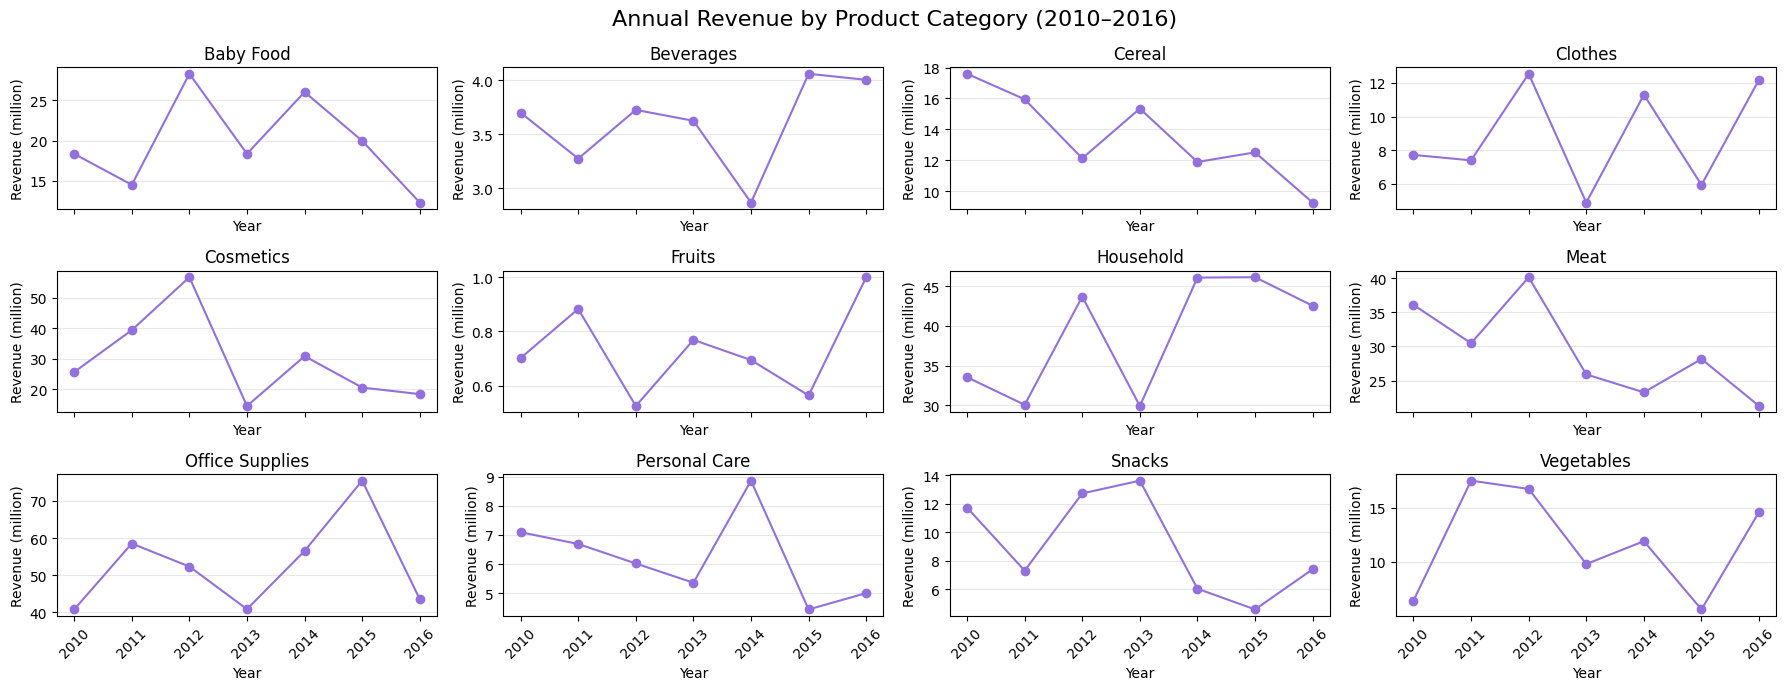

In [ ]:
# Статичні графіки річного доходу за товарними категоріями
# Аналізуємо лише повні роки — 2010–2016

# Створюємо окрему таблицю, залишаючи лише роки до 2016 включно.
# Початкову таблицю category_yearly_table не змінюємо.
category_yearly_table_full_years = category_yearly_table.loc[
    pd.to_numeric(category_yearly_table.index) <= 2016
].copy()

# Перетворюємо індекс таблиці на числові значення років.
years = pd.to_numeric(category_yearly_table_full_years.index)

# Створюємо полотно з 12 графіками:
# 3 рядки по 4 графіки.
# figsize задає загальні ширину та висоту полотна в дюймах.
# sharex=True — усі графіки використовують спільну шкалу років.
fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(18, 7),
    sharex=True
)

# Перебираємо всі графіки та назви товарних категорій.
# axes.flat дає змогу послідовно звертатися до всіх 12 графіків,
# а zip поєднує кожен графік із відповідною категорією.
for ax, category in zip(
    axes.flat,
    category_yearly_table_full_years.columns
):
    # Отримуємо річний дохід поточної категорії.
    # Перетворюємо значення на числові, якщо це необхідно.
    # Значення, які не вдалося перетворити, стають NaN.
    revenue = pd.to_numeric(
        category_yearly_table_full_years[category],
        errors="coerce"
    )

    # Будуємо лінійний графік:
    # роки — по осі X;
    # дохід у мільйонах — по осі Y;
    # marker="o" додає кружечки в точках даних.
    ax.plot(
        years,
        revenue / 1_000_000,
        marker="o",
        color="#9370DB"
    )

    # Додаємо назву товарної категорії над графіком.
    ax.set_title(category)

    # Відображаємо всі роки на осі X.
    ax.set_xticks(years)

    # Повертаємо підписи років на 45 градусів,
    # щоб вони не накладалися один на одного.
    ax.tick_params(axis="x", rotation=45)

    # Додаємо горизонтальну сітку для зручності порівняння.
    ax.grid(axis="y", alpha=0.3)

    # Підписуємо осі.
    ax.set_xlabel("Year")
    ax.set_ylabel("Revenue (million)")

# Додаємо спільний заголовок для всіх 12 графіків.
fig.suptitle(
    "Annual Revenue by Product Category (2010–2016)",
    fontsize=16
)

# Автоматично налаштовуємо відступи між графіками.
plt.tight_layout()

# Відображаємо всі графіки.
plt.show()


### Висновок за динамікою доходу за категоріями товарів

Динаміка доходу відрізнялася залежно від категорії товарів. У більшості категорій спостерігалися коливання доходу з року в рік, без стабільного зростання або зниження протягом усього досліджуваного періоду.

У категорії Office Supplies дохід суттєво коливався, з піками у 2011 та 2015 роках. У Cosmetics після досягнення найвищого показника у 2012 році відбулося різке падіння у 2013 році, а в наступні роки спостерігалося часткове відновлення. У Household високі показники доходу спостерігалися у 2014–2016 роках, тоді як у Meat після високих значень у 2010–2012 роках простежувалася тенденція до зниження.

У категоріях Fruits, Beverages і Personal Care зміни доходу були менш помітними в абсолютних значеннях. Водночас це не обов’язково означає, що відносні коливання в цих категоріях були незначними.

Отже, динаміка доходу за категоріями характеризувалася переважно коливаннями, а окремі категорії мали виражені піки, падіння або періоди відновлення.



### 3.8.3. Динаміка доходу за країнами
Аналіз змін доходу за роками в різних країнах.

In [ ]:
# Знаходимо топ-10 країн за загальним доходом за 2010–2016 роки.
# Країни з невідомою назвою не враховуємо.
top_10_country = (
    sales_data_full_years[
        sales_data_full_years["country"] != "Unknown"
    ]
    .groupby("country")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Залишаємо в таблиці продажів лише ці 10 країн.
top_10_country_sales = sales_data_full_years[
    sales_data_full_years["country"].isin(top_10_country.index)
]

# Групуємо дані за роком і країною
# та обчислюємо сумарний дохід для кожної групи.
country_yearly_sales = top_10_country_sales.groupby(
    ["order_year", "country"]
)["revenue"].sum()

# Перетворюємо результати на таблицю:
# рядки — роки, стовпці — країни.
country_yearly_table = country_yearly_sales.unstack()

# Відображаємо отриману таблицю.
display(country_yearly_table)

country,Andorra,Bosnia and Herzegovina,Czech Republic,Hungary,Malta,Portugal,Russia,San Marino,Slovakia,Ukraine
order_year,,,,,,,,,,
2010,10463527.98,1331049.52,8110413.3,10420812.68,4793614.62,3372587.5,11983040.08,2387947.07,2548346.18,3194980.65
2011,2222978.33,2520932.36,15639309.03,6254135.62,11205717.27,3794478.66,8287896.36,1249469.12,2617824.86,8946152.38
2012,8720081.94,20506108.34,2217746.82,5121757.86,8960734.94,7537536.66,1040770.49,9356740.99,13468163.42,13994664.31
2013,3159874.49,4399195.84,1419947.1,2202210.84,2002747.85,5279022.48,8054117.7,4935779.21,4158902.63,345008.95
2014,4491127.58,397495.31,14761657.41,6852809.47,5853272.61,18823812.24,6740089.28,7143329.27,4919926.13,8028817.86
2015,1884229.67,17905347.83,6911639.34,5584038.11,9906741.21,4654916.19,4328215.96,6887135.47,6198406.03,5631454.86
2016,15724851.18,3057379.29,1775727.68,5495519.46,3844742.94,3709836.11,613524.18,9500466.98,8997495.22,5764026.0


In [ ]:
# Залишаємо для графіка лише повні роки — 2010–2016
country_yearly_table_full_years = country_yearly_table.loc[
    pd.to_numeric(country_yearly_table.index) <= 2016
].copy()

# Створюємо список країн
countries = country_yearly_table_full_years.columns.tolist()

# Створюємо випадаючий список
country_filter = widgets.Dropdown(
    options=countries,
    value=countries[0],
    description="Country:",
    layout=widgets.Layout(width="250px")
)

# Створюємо область для графіка
country_plot_output = widgets.Output(
    layout=widgets.Layout(width="750px")
)

# Функція побудови та оновлення графіка
def update_country_chart(change=None):
    country = country_filter.value

    with country_plot_output:
        clear_output(wait=True)

        fig, ax = plt.subplots(figsize=(9, 5))

        ax.plot(
            country_yearly_table_full_years.index,
            country_yearly_table_full_years[country] / 1_000_000,
            marker="o",
            color="#9370DB"
        )

        ax.set_title(f"Annual Revenue — {country}")
        ax.set_xlabel("Year")
        ax.set_ylabel("Revenue (million)")

        ax.set_xticks(country_yearly_table_full_years.index)
        ax.grid(axis="y", alpha=0.3)

        plt.tight_layout()
        plt.show()
        plt.close(fig)

# Оновлюємо графік при виборі іншої країни
country_filter.observe(update_country_chart, names="value")

# Будуємо початковий графік
update_country_chart()

# Розміщуємо список і графік поруч
country_view = widgets.HBox(
    [country_filter, country_plot_output],
    layout=widgets.Layout(align_items="flex-start")
)

display(country_view)

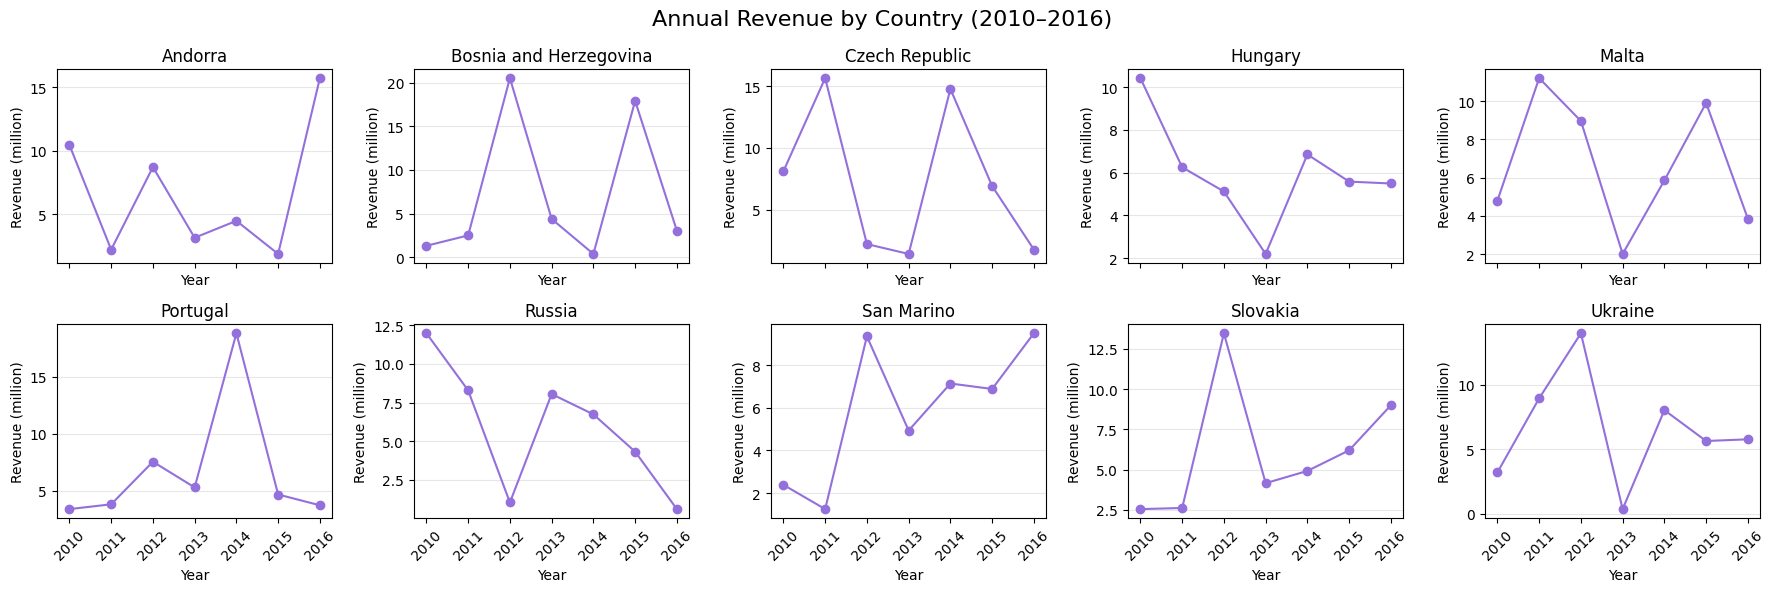

In [ ]:
# Статичні графіки доходу за країнами
# Відображаємо лише повні роки — 2010–2016

# Перетворюємо індекс таблиці на числові значення років.
# Це потрібно для коректного відображення років на осі X.
years = pd.to_numeric(country_yearly_table_full_years.index)

# Створюємо полотно з 10 графіками:
# 2 рядки по 5 графіків у кожному.
# sharex=True означає, що графіки використовують спільну шкалу осі X.
fig, axes = plt.subplots(
    nrows=2,
    ncols=5,
    figsize=(18, 6),
    sharex=True
)

# Перебираємо графіки та країни одночасно:
# ax — поточна область для малювання графіка;
# country — назва країни з таблиці.
for ax, country in zip(
    axes.flat,
    country_yearly_table_full_years.columns
):
    # Беремо дохід вибраної країни за всі роки.
    # errors="coerce" перетворює значення, які не вдалося
    # розпізнати як числа, на NaN (відсутнє числове значення).
    revenue = pd.to_numeric(
        country_yearly_table_full_years[country],
        errors="coerce"
    )

    # Будуємо лінійний графік:
    # years — роки по осі X;
    # revenue / 1_000_000 — дохід у мільйонах по осі Y.
    ax.plot(
        years,
        revenue / 1_000_000,
        marker="o",
        color="#9370DB"
    )

    # Додаємо назву країни над відповідним графіком.
    ax.set_title(country)

    # Встановлюємо роки, які мають бути підписані на осі X.
    ax.set_xticks(years)

    # Повертаємо підписи років на 45 градусів,
    # щоб вони не накладалися один на одного.
    ax.tick_params(axis="x", rotation=45)

    # Додаємо сітку лише по горизонталі,
    # щоб було зручніше порівнювати значення доходу.
    ax.grid(axis="y", alpha=0.3)

    # Підписуємо осі кожного невеликого графіка.
    ax.set_xlabel("Year")
    ax.set_ylabel("Revenue (million)")

# Додаємо загальний заголовок для всіх десяти графіків.
fig.suptitle(
    "Annual Revenue by Country (2010–2016)",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Висновок за динамікою доходу за країнами

Дохід у досліджуваних країнах істотно коливався з року в рік, причому динаміка відрізнялася залежно від країни. Порівняння показників за 2010 і 2016 роки показало зростання доходу в семи країнах: Андоррі, Боснії і Герцеговині, Македонії, Португалії, Сан-Марино, Словаччині та Україні. У Чехії, Мальті та Росії дохід за цей період знизився.

Водночас у деяких країнах спостерігалися значні коливання протягом досліджуваного періоду. Наприклад, у Македонії дохід зріс із 2,29 млн у 2010 році до 16,45 млн у 2015 році, а у 2016 році становив 5,26 млн. Це свідчить про те, що навіть за загального зростання між початковим і кінцевим роками динаміка доходу могла бути нерівномірною.

Отже, результати демонструють різні траєкторії зміни доходу в окремих країнах: поряд зі зростанням або зниженням між 2010 і 2016 роками спостерігалися помітні річні коливання. Дані за 2017 рік охоплюють лише період до 23 липня, тому їх варто розглядати окремо від показників повних календарних років.

### 3.8.4. Динаміка доходу за регіонами
Аналіз змін доходу за роками в різних регіонах.

In [ ]:
# Виключаємо рядки, у яких регіон невідомий
known_regions = sales_data_full_years[
    sales_data_full_years["region"] != "Unknown"
]

# Групуємо дані за роком і регіоном та підсумовуємо дохід
region_yearly_sales = known_regions.groupby(
    ["order_year", "region"]
)["revenue"].sum()

# Перетворюємо результат на таблицю:
# рядки — роки, стовпці — регіони
region_yearly_table = region_yearly_sales.unstack()

# Відображаємо отриману таблицю
display(region_yearly_table)

region,Asia,Europe
order_year,,
2010,14040364.13,188214068.09
2011,4347439.86,209864906.73
2012,21790920.12,245769462.75
2013,12331488.07,163024640.21
2014,12276568.25,204698038.71
2015,14766917.42,199220094.77
2016,6243819.98,175034269.87


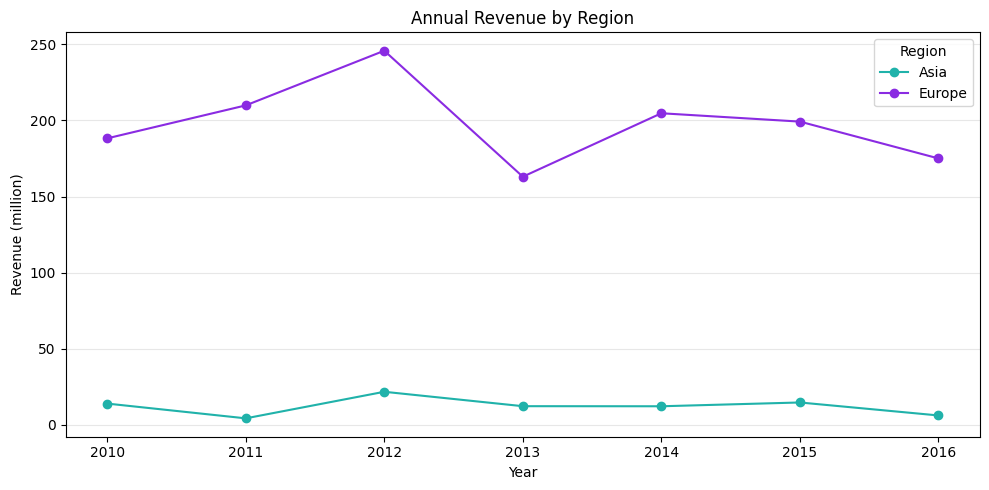

In [ ]:
# Створюємо графік динаміки доходу за регіонами

# Кольори для регіонів
region_colors = {
    "Europe": "#8A2BE2",
    "Asia": "#20B2AA"
}

fig, ax = plt.subplots(figsize=(10, 5))

# Перебираємо кожен регіон у таблиці
for region in region_yearly_table.columns:
    ax.plot(
        region_yearly_table.index,
        region_yearly_table[region] / 1_000_000,
        marker="o",
        label=region,
        color=region_colors[region]
    )

ax.set_title("Annual Revenue by Region")
ax.set_xlabel("Year")
ax.set_ylabel("Revenue (million)")

ax.set_xticks(region_yearly_table.index)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Region")

plt.tight_layout()
plt.show()
plt.close(fig)

### Висновок за динамікою доходу за регіонами

У жодному з регіонів не спостерігалося стабільного зростання доходу протягом досліджуваного періоду. У Європі дохід зростав до 2012 року, після чого різко знизився у 2013 році, частково відновився у 2014 році та надалі зменшувався. В Азії дохід був значно нижчим, ніж у Європі, тому його зміни на спільному графіку візуально менш помітні. У 2012 році дохід в Азії зріс порівняно з попереднім роком, а в наступні роки коливався. У 2016 році дохід в обох регіонах був нижчим, ніж у 2010 році.

### 3.8.5. Аналіз продажів за днями тижня


In [ ]:
# Додаємо стовпець із назвами днів тижня
# на основі дати замовлення
sales_data_full_years["week_day"] = (
    sales_data_full_years["order_date"].dt.day_name()
)

# Перевіряємо дати та відповідні дні тижня
# для перших п'яти замовлень
sales_data_full_years[["order_date", "week_day"]].head()

,order_date,week_day
0,2014-10-08,Wednesday
1,2016-08-11,Thursday
2,2014-07-18,Friday
4,2012-08-11,Saturday
5,2015-03-15,Sunday


In [ ]:
# Групуємо дані за днями тижня та обчислюємо сумарний дохід
# Розташовуємо дні в порядку від понеділка до неділі
weekday_revenue = sales_data_full_years.groupby("week_day")["revenue"].sum().reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
])
display(weekday_revenue)

,revenue
week_day,
Monday,246315420.72
Tuesday,196098443.88
Wednesday,237260229.98
Thursday,205426022.29
Friday,246037684.32
Saturday,209567123.58
Sunday,224824009.28


In [ ]:
# Групуємо дані за днями тижня та рахуємо кількість унікальних замовлень
# Розташовуємо дні в порядку від понеділка до неділі
weekday_count_orders = sales_data_full_years.groupby("week_day")["order_id"].nunique().reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
])

display(weekday_count_orders)

,order_id
week_day,
Monday,186
Tuesday,165
Wednesday,176
Thursday,160
Friday,162
Saturday,185
Sunday,188


In [ ]:
# Обчислюємо середній дохід на одне замовлення для кожного дня тижня
avg_revenue_order = weekday_revenue / weekday_count_orders
display(avg_revenue_order.round(2))

,0
week_day,
Monday,1324276.46
Tuesday,1188475.42
Wednesday,1348069.49
Thursday,1283912.64
Friday,1518751.14
Saturday,1132795.26
Sunday,1195872.39


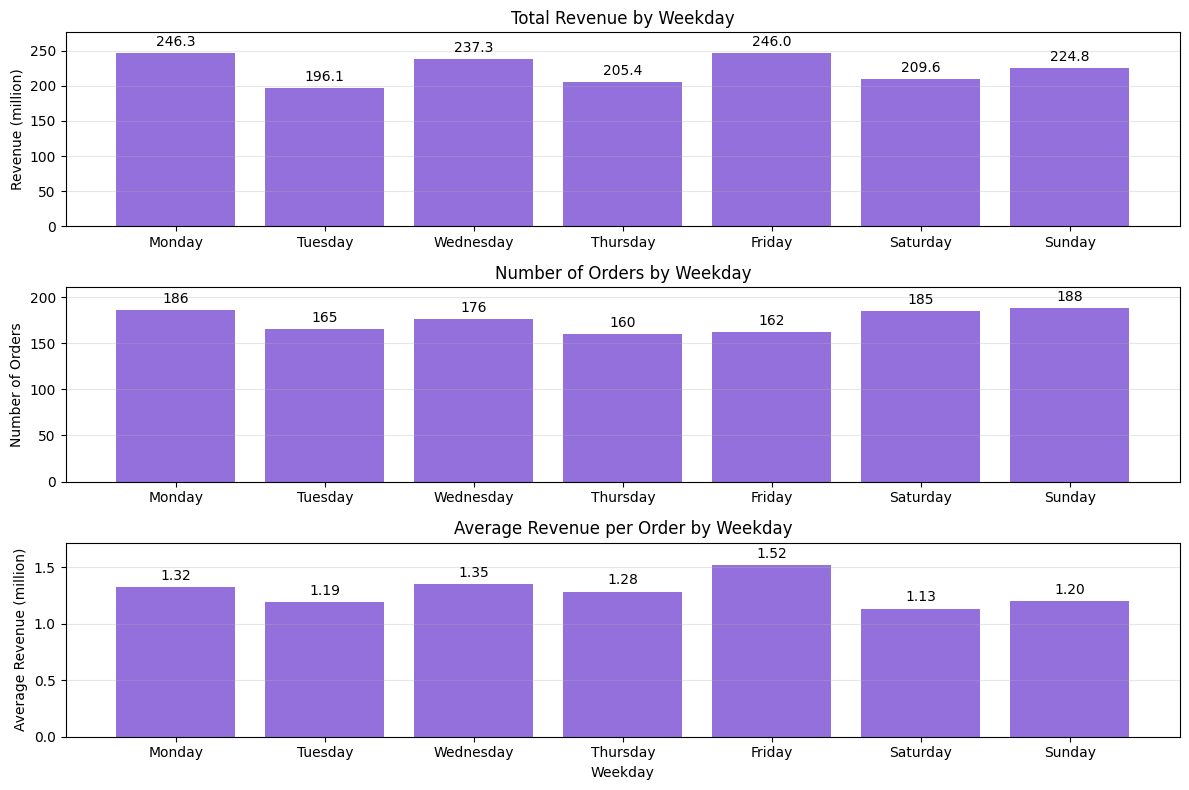

In [ ]:
# Створюємо одну фігуру з трьома графіками, розташованими один під одним
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# 1. Будуємо графік сумарного доходу за днями тижня
bars1 = axes[0].bar(
    weekday_revenue.index,
    weekday_revenue / 1_000_000,
    color="#9370DB"
)

axes[0].set_title("Total Revenue by Weekday")
axes[0].set_ylabel("Revenue (million)")
axes[0].bar_label(bars1, fmt="%.1f", padding=3)
axes[0].set_ylim(top=(weekday_revenue / 1_000_000).max() * 1.12)
axes[0].grid(axis="y", alpha=0.3)


# 2. Будуємо графік кількості замовлень за днями тижня
bars2 = axes[1].bar(
    weekday_count_orders.index,
    weekday_count_orders,
    color="#9370DB"
)

axes[1].set_title("Number of Orders by Weekday")
axes[1].set_ylabel("Number of Orders")
axes[1].bar_label(bars2, fmt="%.0f", padding=3)
axes[1].set_ylim(top=weekday_count_orders.max() * 1.12)
axes[1].grid(axis="y", alpha=0.3)


# 3. Будуємо графік середнього доходу на одне замовлення
bars3 = axes[2].bar(
    avg_revenue_order.index,
    avg_revenue_order / 1_000_000,
    color="#9370DB"
)

axes[2].set_title("Average Revenue per Order by Weekday")
axes[2].set_ylabel("Average Revenue (million)")
axes[2].set_xlabel("Weekday")
axes[2].bar_label(bars3, fmt="%.2f", padding=3)
axes[2].set_ylim(top=(avg_revenue_order / 1_000_000).max() * 1.13)
axes[2].grid(axis="y", alpha=0.3)

# Показуємо назви днів тижня під кожним графіком
for ax in axes:
    ax.tick_params(axis="x", labelbottom=True)

# Налаштовуємо відступи та відображаємо всі три графіки
plt.tight_layout()
plt.show()
plt.close(fig)

Аналіз продажів за днями тижня показав, що найбільший сумарний дохід припадав на понеділок (275,5 млн), тоді як найбільшу кількість замовлень було зафіксовано в неділю (207). Водночас у п'ятницю спостерігався найвищий середній дохід на одне замовлення (близько 1,50 млн), хоча цей день не був лідером за кількістю замовлень. У неділю, навпаки, середній дохід на одне замовлення був найнижчим (близько 1,16 млн). Отже, дні з найбільшою кількістю замовлень не обов'язково забезпечують найбільший сумарний дохід. Різниця в сумарному доході пов'язана як із кількістю замовлень, так і з середнім доходом на одне замовлення.

### 3.8.6. Дослідження сезонності продажів

Для виявлення можливих сезонних закономірностей досліджуємо розподіл продажів за днями тижня та календарними місяцями. Аналіз виконуємо за повні календарні роки — з 2010 до 2016 року. Це дає змогу порівняти частки продажів за днями тижня в різні роки, а також середній дохід за кожним календарним місяцем.

#### Частина 1. Дослідження тижневої сезонності за категоріями
Для виявлення можливих закономірностей у продажах окремих товарних категорій будуємо теплову карту частки продажів за днями тижня та роками. Інтерактивна візуалізація дає змогу обирати категорію й порівнювати розподіл продажів упродовж 2010–2016 років, щоб визначити наявність або відсутність стійких тижневих тенденцій.

In [ ]:
# Визначаємо порядок днів тижня для стовпців теплової карти
weekly_seasonality_day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Отримуємо список років, які є в таблиці продажів
weekly_seasonality_year_values = sorted(
    sales_data_full_years["order_year"].dropna().unique()
)

# Створюємо окремий список категорій для цього інтерактивного графіка
weekly_seasonality_categories = sorted(
    sales_data_full_years["item_type"].dropna().unique()
)

# Створюємо випадаючий список для вибору категорії товару
weekly_seasonality_category_dropdown = widgets.Dropdown(
    options=weekly_seasonality_categories,
    value=weekly_seasonality_categories[0],
    description="Category:",
    layout=widgets.Layout(width="250px")
)

# Створюємо окрему область для відображення теплової карти
weekly_seasonality_heatmap_output = widgets.Output(
    layout=widgets.Layout(width="800px")
)


# Створюємо функцію побудови та оновлення теплової карти
def update_weekly_seasonality_heatmap(
    weekly_seasonality_change=None
):
    # Отримуємо категорію, вибрану у випадаючому списку
    weekly_seasonality_selected_category = (
        weekly_seasonality_category_dropdown.value
    )

    # Виводимо графік у призначену для нього область
    with weekly_seasonality_heatmap_output:

        # Очищаємо попередню теплову карту перед побудовою нової
        clear_output(wait=True)

        # Відбираємо з sales_data рядки лише для вибраної категорії
        weekly_seasonality_filtered_data = sales_data_full_years.loc[
            sales_data_full_years["item_type"]
            == weekly_seasonality_selected_category
        ]

        # Групуємо продажі за роками та днями тижня,
        # підсумовуємо кількість проданих одиниць
        # Перетворюємо дні тижня на стовпці та впорядковуємо їх
        weekly_seasonality_units_matrix = (
            weekly_seasonality_filtered_data
            .groupby(["order_year", "week_day"])["units_sold"]
            .sum()
            .unstack()
            .reindex(
                index=weekly_seasonality_year_values,
                columns=weekly_seasonality_day_order
            )
            .fillna(0)  # Для відсутніх комбінацій року й дня ставимо 0
            .astype("float64")  # Перетворюємо дані на числовий тип
        )

        # Обчислюємо загальну кількість проданих одиниць
        # вибраної категорії окремо для кожного року
        weekly_seasonality_year_totals = (
            weekly_seasonality_units_matrix.sum(axis=1)
        )

        # Якщо за рік немає жодного продажу категорії,
        # загальна сума дорівнює 0 і відсотки визначити неможливо
        weekly_seasonality_year_totals = (
            weekly_seasonality_year_totals.replace(0, np.nan)
        )

        # Обчислюємо частку продажів кожного року
        # за днями тижня у відсотках
        weekly_seasonality_percent_matrix = (
            weekly_seasonality_units_matrix.div(
                weekly_seasonality_year_totals,
                axis=0  # Ділимо кожен рядок на суму відповідного року
            ) * 100
        )

        # Створюємо фігуру та область для теплової карти
        weekly_seasonality_figure, weekly_seasonality_axis = (
            plt.subplots(figsize=(12, 7))
        )

        # Будуємо теплову карту з однаковою шкалою кольорів
        # для всіх категорій, щоб можна було порівнювати результати
        sns.heatmap(
            weekly_seasonality_percent_matrix,
            annot=True,  # Показуємо відсотки в клітинках
            fmt=".1f",  # Округлюємо підписи до одного знака після коми
            cmap="Purples",  # Використовуємо фіолетову палітру
            linewidths=0.5,  # Додаємо межі між клітинками
            vmin=0,
            vmax=30,
            cbar_kws={"label": "Share of annual sales (%)"},
            ax=weekly_seasonality_axis
        )

        # Додаємо заголовок і підписи осей
        weekly_seasonality_axis.set_title(
            f"Share of {weekly_seasonality_selected_category} "
            "Sales by Weekday and Year"
        )
        weekly_seasonality_axis.set_xlabel("Weekday")
        weekly_seasonality_axis.set_ylabel("Year")

        # Налаштовуємо відступи, показуємо графік і звільняємо фігуру
        plt.tight_layout()
        plt.show()
        plt.close(weekly_seasonality_figure)


# Оновлюємо теплову карту, коли користувач вибирає іншу категорію
weekly_seasonality_category_dropdown.observe(
    update_weekly_seasonality_heatmap,
    names="value"
)

# Розташовуємо випадаючий список ліворуч, теплову карту праворуч
weekly_seasonality_category_view = widgets.VBox(
    [
        weekly_seasonality_category_dropdown,
        weekly_seasonality_heatmap_output
    ],
    layout=widgets.Layout(align_items="flex-start")
)

# Відображаємо інтерактивний елемент
display(weekly_seasonality_category_view)

# Будуємо початкову теплову карту для вибраної категорії
update_weekly_seasonality_heatmap()

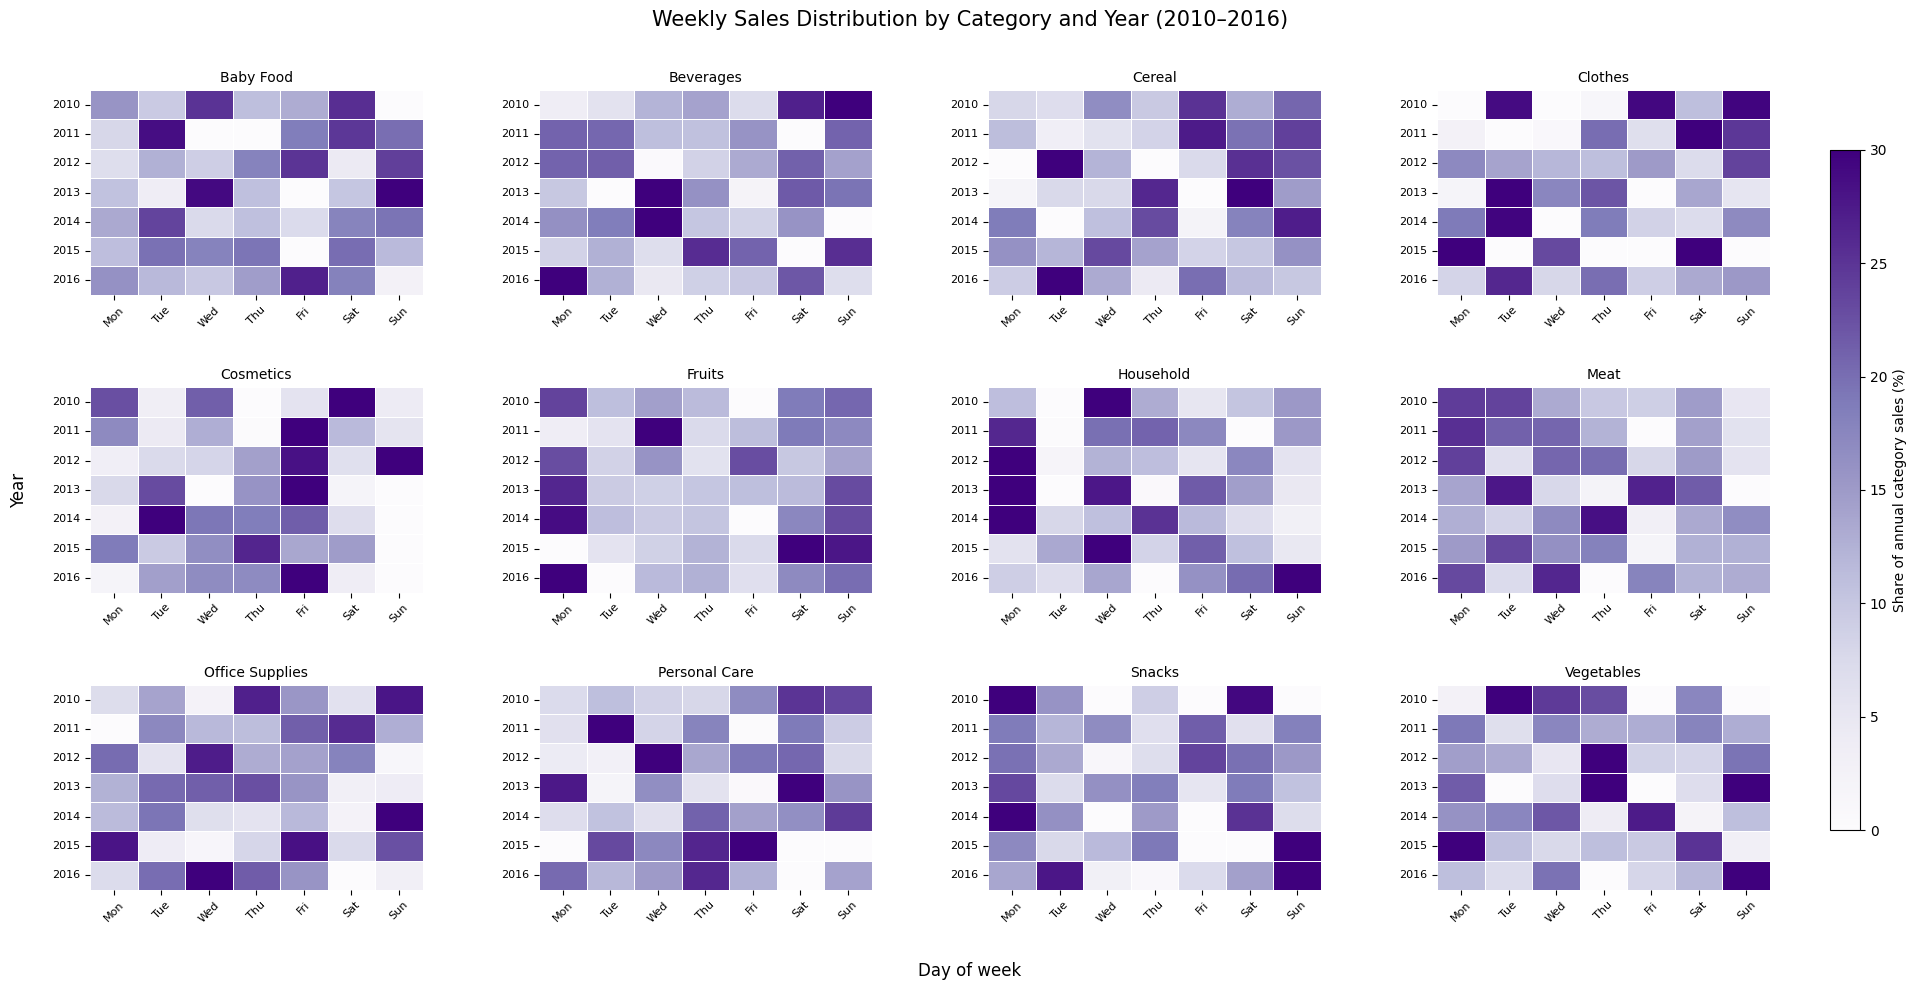

In [ ]:
# Статичні теплові карти тижневої сезонності для 12 категорій
# Використовуємо повні роки — 2010–2016

# Визначаємо порядок днів тижня
weekly_day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Короткі назви днів тижня для компактних графіків
weekly_day_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Отримуємо роки та категорії з таблиці без 2017 року
years = sorted(
    sales_data_full_years["order_year"].dropna().unique()
)
categories = sorted(
    sales_data_full_years["item_type"].dropna().unique()
)

# Встановлюємо однакову шкалу кольорів для всіх карт
vmin = 0
vmax = 30

# Створюємо полотно: 3 рядки по 4 теплові карти
fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(20, 10)
)

# Перебираємо графіки та категорії по черзі
for ax, category in zip(axes.flat, categories):

    # Відбираємо замовлення лише для поточної категорії
    category_data = sales_data_full_years[
        sales_data_full_years["item_type"] == category
    ]

    # Групуємо кількість проданих одиниць за роком і днем тижня
    units_matrix = (
        category_data
        .groupby(["order_year", "week_day"])["units_sold"]
        .sum()
        .unstack()
        # Зберігаємо всі роки та правильний порядок днів
        .reindex(index=years, columns=weekly_day_order)
        # Для відсутніх комбінацій року й дня встановлюємо 0
        .fillna(0)
        .astype(float)
    )

    # Обчислюємо загальну кількість проданих одиниць
    # у кожному році для цієї категорії
    year_totals = units_matrix.sum(axis=1)

    # Уникаємо ділення на нуль, якщо за рік продажів не було
    year_totals = year_totals.replace(0, np.nan)

    # Розраховуємо частку продажів за кожним днем тижня
    # у межах відповідного року, у відсотках
    percent_matrix = (
        units_matrix.div(year_totals, axis=0) * 100
    )

    # Будуємо теплову карту без числових підписів
    sns.heatmap(
        percent_matrix,
        annot=False,
        cmap="Purples",
        vmin=vmin,
        vmax=vmax,
        linewidths=0.4,
        xticklabels=weekly_day_labels,
        yticklabels=years,
        cbar=False,  # Спільну шкалу додамо окремо нижче
        ax=ax
    )

    # Додаємо назву категорії та налаштовуємо підписи
    ax.set_title(category, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

# Створюємо спільну шкалу кольорів для всіх 12 карт
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

color_scale = ScalarMappable(
    norm=Normalize(vmin=vmin, vmax=vmax),
    cmap="Purples"
)
color_scale.set_array([])

# Додаємо спільний заголовок і підписи осей
fig.suptitle(
    "Weekly Sales Distribution by Category and Year (2010–2016)",
    fontsize=15
)
fig.supxlabel("Day of week")
fig.supylabel("Year")

# Вручну налаштовуємо розташування 12 графіків:
# right=0.90 залишає вільне місце праворуч для шкали кольорів
# wspace — відстань між графіками по горизонталі
# hspace — відстань між графіками по вертикалі
fig.subplots_adjust(
    left=0.06,
    right=0.90,
    bottom=0.10,
    top=0.90,
    wspace=0.35,
    hspace=0.45
)

# Створюємо окрему область для шкали кольорів праворуч.
# Чотири числа задають її положення та розмір:
# [відступ зліва, відступ знизу, ширина, висота]
colorbar_axis = fig.add_axes([0.93, 0.16, 0.015, 0.68])

# Розміщуємо шкалу в окремій області, щоб вона не перекривала карти
fig.colorbar(
    color_scale,
    cax=colorbar_axis,
    label="Share of annual category sales (%)"
)

# Відображаємо всі теплові карти
plt.show()

**Висновок за тижневою сезонністю**

Теплову карту використано для дослідження частки проданих одиниць за днями тижня в межах кожної товарної категорії та року. За результатами візуального аналізу не виявлено стабільних повторюваних закономірностей у розподілі продажів за днями тижня.

Окремі підвищені значення для певних категорій і днів тижня спостерігаються нерегулярно. З огляду на невелику кількість замовлень у відповідних групах ці відмінності не дають достатніх підстав вважати їх стійкими закономірностями.

Отже, наявні дані не підтверджують вираженої тижневої сезонності продажів у досліджуваних товарних категоріях.

#### Частина 2. Місячна сезонність

Для дослідження можливих закономірностей у зміні доходу залежно від календарного місяця побудуємо дві візуалізації за 2010–2016 роки. Теплова карта відображатиме дохід за кожним місяцем окремо в межах кожного року, що дасть змогу оцінити повторюваність піків і спадів. Стовпчикова діаграма показуватиме середній дохід за кожен календарний місяць за досліджуваний період, щоб порівняти місяці між собою.

Кількість пропусків у доході: 0


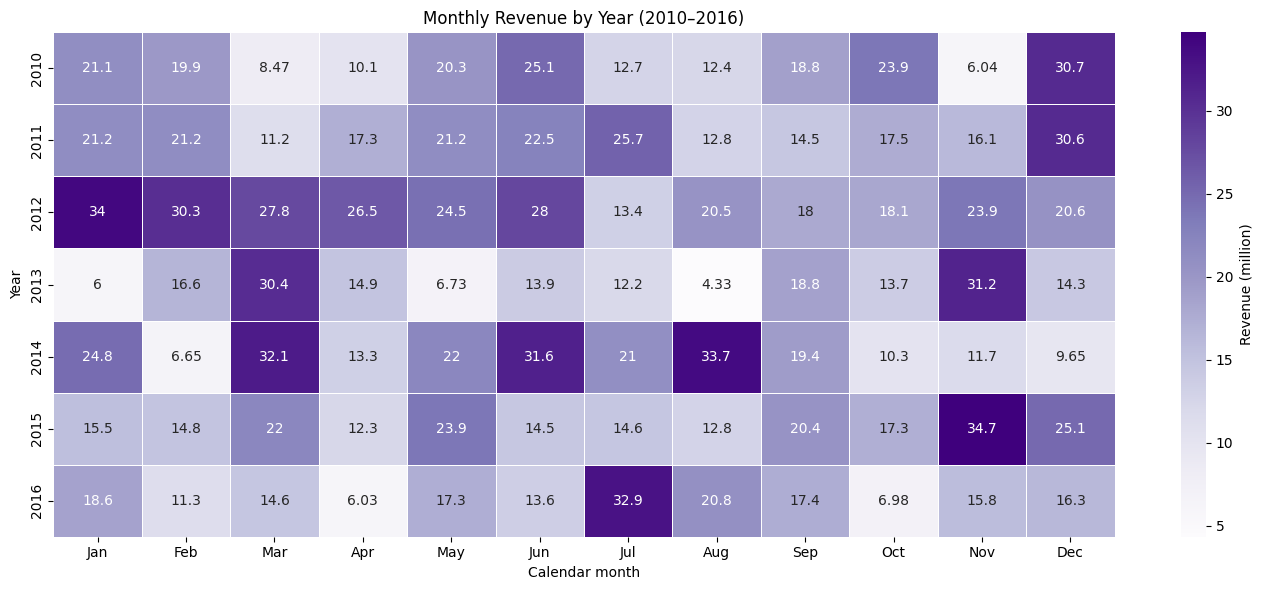

In [ ]:
# Дослідження місячної сезонності за повні роки — 2010–2016

# Створюємо робочу копію даних, щоб не змінювати основну таблицю
seasonality_data = sales_data_full_years.copy()

# Отримуємо рік і номер місяця з дати замовлення
seasonality_data["order_year"] = (
    seasonality_data["order_date"].dt.year
)
seasonality_data["month_num"] = (
    seasonality_data["order_date"].dt.month
)

# Перетворюємо дохід на числовий тип перед групуванням.
# Це потрібно, щоб Pandas правильно підсумував значення,
# а теплова карта отримала числові дані.
seasonality_data["revenue"] = pd.to_numeric(
    seasonality_data["revenue"],
    errors="coerce"
)

# Перевіряємо, чи є відсутні або нерозпізнані значення доходу
print(
    "Кількість пропусків у доході:",
    seasonality_data["revenue"].isna().sum()
)

# Групуємо дані за роком і місяцем та підсумовуємо дохід.
# Рядки матриці — роки, стовпці — номери місяців.
monthly_revenue_matrix = (
    seasonality_data
    .groupby(["order_year", "month_num"])["revenue"]
    .sum()
    .unstack()
    # Забезпечуємо наявність усіх 12 місяців
    # і правильний порядок років та місяців
    .reindex(
        index=range(2010, 2017),
        columns=range(1, 13)
    )
    # Для відсутніх комбінацій року та місяця ставимо 0
    .fillna(0)
    # Гарантуємо числовий тип для побудови теплової карти
    .astype(float)
)

# Обчислюємо середній дохід за кожен календарний місяць
# за 2010–2016 роки та переводимо його в мільйони.
# Зберігаємо цей результат для окремого стовпчикового графіка.
average_monthly_revenue = (
    monthly_revenue_matrix.mean(axis=0) / 1_000_000
)

# Переводимо значення матриці в мільйони для теплової карти
monthly_revenue_matrix = monthly_revenue_matrix / 1_000_000

# Замінюємо номери місяців короткими англійськими назвами
months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]
monthly_revenue_matrix.columns = months

# Створюємо полотно для теплової карти
fig, ax = plt.subplots(figsize=(14, 6))

# Будуємо теплову карту місячного доходу за роками
sns.heatmap(
    monthly_revenue_matrix,
    annot=True,                 # Показуємо числа в клітинках
    fmt=".3g",                  # Три значущі цифри
    cmap="Purples",             # Фіолетова палітра
    linewidths=0.5,             # Межі між клітинками
    cbar_kws={"label": "Revenue (million)"},
    ax=ax
)

# Додаємо заголовок і підписи осей
ax.set_title("Monthly Revenue by Year (2010–2016)")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Year")

# Налаштовуємо відступи та показуємо графік
plt.tight_layout()
plt.show()

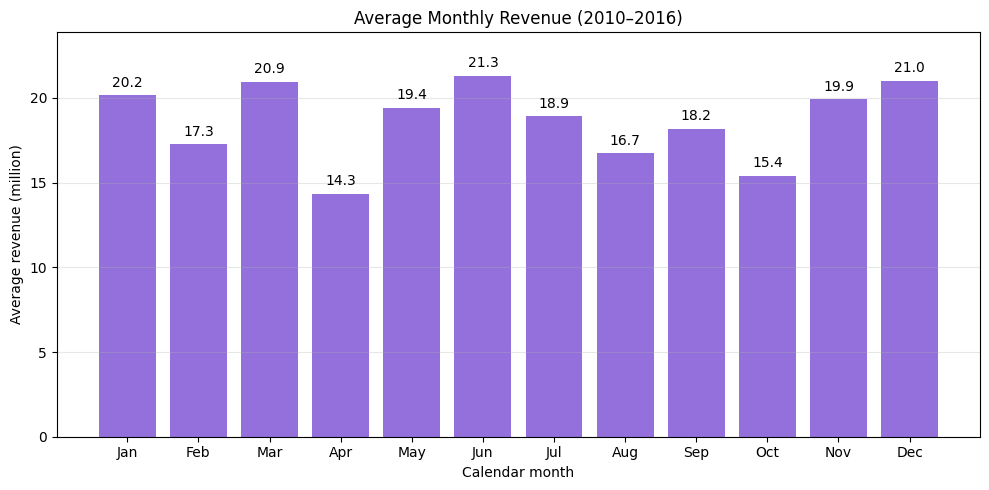

In [ ]:
# Будуємо стовпчиковий графік середнього місячного доходу
# за повні роки 2010–2016

fig, ax = plt.subplots(figsize=(10, 5))

# Будуємо стовпчики та зберігаємо їх у змінній bars
bars = ax.bar(
    months,
    average_monthly_revenue.values,
    color="#9370DB"
)

# Додаємо підписи над кожним стовпчиком
for bar in bars:
    # Отримуємо висоту стовпчика — середній дохід
    revenue = bar.get_height()

    # Розміщуємо значення над відповідним стовпчиком
    ax.annotate(
        f"{revenue:.1f}",  # Округлюємо до одного знака після коми
        xy=(bar.get_x() + bar.get_width() / 2, revenue),
        xytext=(0, 4),          # Відступ від верхівки стовпчика
        textcoords="offset points",
        ha="center",            # Вирівнюємо по горизонталі
        va="bottom"             # Вирівнюємо по нижньому краю тексту
    )

# Додаємо заголовок і підписи осей
ax.set_title("Average Monthly Revenue (2010–2016)")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Average revenue (million)")

# Залишаємо вгорі місце для підписів
ax.set_ylim(0, average_monthly_revenue.max() * 1.12)

# Додаємо горизонтальну сітку
ax.grid(axis="y", alpha=0.3)

# Розміщуємо елементи графіка та показуємо результат
plt.tight_layout()
plt.show()

### Висновок за місячною сезонністю

За результатами аналізу доходу за 2010–2016 роки встановлено, що середній дохід відрізняється залежно від календарного місяця. Найвищі середні значення спостерігалися в червні (21,3 млн), грудні (21 млн) і березні (20,9 млн), а найнижчі — у квітні (14,3 млн) та жовтні (15,4 млн).

Водночас теплова карта показує, що місяці з найбільшим доходом змінювалися з року в рік: наприклад, у 2010–2011 роках найбільші значення припадали на грудень, у 2014 році — на серпень, а у 2016 році — на липень. Отже, підвищений дохід у певні місяці не повторювався стабільно протягом усього досліджуваного періоду.

Таким чином, **чіткої повторюваної місячної сезонності продажів за досліджуваними даними не виявлено**. Водночас спостерігаються відмінності в середньому доході між календарними місяцями, які не утворюють стабільної закономірності з року в рік.

## Фінальні висновки та бізнес-рекомендації

За результатами аналізу 1 328 замовлень із 45 країн і 12 товарних категорій загальний дохід становить **1,70 млрд**, а прибуток — **501,43 млн** за рентабельності продажів близько **29,46%**. Аналіз виявив відмінності в прибутковості товарних категорій, результатах країн і каналів продажів, а також зміни доходу в часі. На основі отриманих результатів можна виділити такі напрями для бізнес-рішень.

1. **Перевірити чинники нижчої рентабельності Office Supplies і Meat.** Office Supplies забезпечує найбільший дохід (402,2 млн), але його рентабельність становить 19,39%, що нижче за загальний показник компанії (29,46%). У категорії Meat рентабельність ще нижча — 13,6%. Доцільно дослідити співвідношення доходу, витрат і прибутку на рівні окремих товарів, щоб визначити, які позиції найбільше впливають на рентабельність цих категорій. Для порівняння, Clothes має найвищу рентабельність (67,2%), а Cosmetics — найбільший загальний прибуток (92,7 млн) і найбільший прибуток на одну продану одиницю (173,87). Ці категорії можуть слугувати орієнтиром для порівняння фінансових показників. Для детальнішого дослідження потрібні дані про продажі окремих товарів, оскільки наявний набір даних дає змогу аналізувати результати лише на рівні категорій.

2. **Оцінити економіку категорії Fruits з урахуванням прибутку на одиницю.** Fruits посідає третє місце за кількістю проданих одиниць (592 тис.), але має найменші загальні дохід (5,5 млн) і прибуток (1,4 млн). Водночас прибуток на одну продану одиницю становить 2,41; рентабельність категорії дорівнює 25,83%. Це свідчить про невеликий прибуток у розрахунку на одиницю, але не означає автоматично, що категорія є збитковою або неефективною. Доцільно порівняти ціни, собівартість і структуру асортименту окремих товарів Fruits, щоб визначити, чи є можливості підвищити прибуток на одиницю без необґрунтованого скорочення обсягу продажів.

3. **Визначити причини зниження доходу в останні повні роки спостереження.** Після зростання у 2010–2012 роках дохід знизився у 2013 році, частково відновився у 2014-му, а у 2015–2016 роках знову падав. Доцільно порівняти показники за 2014–2016 роки в розрізі категорій і країн, щоб визначити, де падіння було найбільшим. Для цих напрямів варто окремо перевірити кількість замовлень і середній дохід на замовлення: це допоможе з’ясувати, чи пов’язане зниження з меншою кількістю покупок або зі зміною їхньої вартості. Дані за 2017 рік охоплюють лише частину року, тому їх не слід безпосередньо порівнювати з повними роками.

4. **Оцінювати країни за сукупністю фінансових показників.** Чехія має найбільший дохід (53,5 млн), Андорра — найбільший абсолютний прибуток (15,4 млн), а Данія — найвищу рентабельність (35,7%). Це свідчить про відмінності у фінансових результатах країн: лідерство за доходом не обов’язково означає лідерство за прибутком або рентабельністю. Перед зміною пріоритетів продажів чи розподілу маркетингових ресурсів доцільно дослідити структуру товарних категорій і витрат у країнах із найбільшим доходом, а також у країнах із високою рентабельністю. Це допоможе визначити, які товари формують їхні фінансові результати та які відмінності можуть бути важливими для бізнес-рішень.

5. **Врахувати концентрацію продажів у Європі та оцінити можливості інших ринків.** Європа забезпечує 88,5% загального доходу компанії (1 505,65 млн із 1 702,13 млн). Частку розраховано від загального доходу, включно з доходом за 82 замовленнями з невідомим регіоном. Прибуток регіону становить 448,56 млн. Це підтверджує провідну роль Європи в діяльності компанії. Водночас перед розширенням в Азії доцільно порівняти країни регіону за доходом, прибутком і кількістю проданих одиниць, щоб визначити конкретні ринки з потенціалом для розвитку.

6. **Не перерозподіляти ресурси між каналами продажів лише на основі абсолютних показників.** Офлайн-канал забезпечив більший дохід (872 млн проти 830 млн) і прибуток (253 млн проти 248 млн), тоді як рентабельність онлайн-каналу трохи вища — 29,9% проти 29,1% в офлайн-каналу. Отже, офлайн має дещо вищі абсолютні фінансові результати, а онлайн — трохи вищу рентабельність. Перед зміною розподілу маркетингового бюджету доцільно додатково порівняти середній дохід на замовлення та витрати на залучення й обслуговування клієнтів у кожному каналі. Це допоможе оцінити, чи виправдано спрямовувати більше ресурсів в один із каналів.

7. **Перевірити можливості оптимізації доставки.** Середній час доставки відрізняється між країнами: у Хорватії він становить 18,4 дня, а в Угорщині — 32,6 дня. Варто порівняти умови доставки, структуру замовлень і логістичні процеси в цих країнах, щоб визначити можливі причини різниці. Водночас обидва методи кореляційного аналізу показали дуже слабкий позитивний зв’язок між часом доставки та прибутком (Пірсон: r = 0,0603; Спірмен: ρ = 0,0581). Тому наявні дані не дають підстав стверджувати, що скорочення часу доставки саме по собі збільшить прибуток.

8. **Планування роботи за днями тижня.** За днями тижня понеділок має найбільший сукупний дохід, п’ятниця — найбільший середній дохід на замовлення, а неділя — найбільшу кількість замовлень, але найменший середній дохід на замовлення. Доцільно порівняти склад замовлень і категорії товарів у ці дні, перш ніж змінювати графіки роботи або запускати спеціальні пропозиції. Оскільки стабільної щотижневої сезонності для більшості категорій не виявлено, такі рішення варто перевіряти на даних за різні роки.

9. **Врахувати відмінності в середньому доході між місяцями під час планування продажів.** За повні роки 2010–2016 найбільший середній місячний дохід спостерігався в червні (21,3 млн), а найменший — у квітні (14,3 млн). Водночас теплова карта показала, що місяці з найвищими показниками змінювалися з року в рік, тому чіткої повторюваної місячної сезонності не виявлено. Щоб краще зрозуміти причини коливань доходу, доцільно порівняти кількість замовлень і середній дохід на замовлення в різні місяці. Отримані результати можна використовувати для планування продажів, але не як доказ стабільного сезонного попиту. Дані за 2017 рік не включено до цього порівняння, оскільки вони охоплюють лише частину року.

